# Universidad de la Salle
## Maestría en Inteligencia Artificial
### Machine Learning - Grupo 01
---
#### Realizado por:
    Ing. Camilo Andrés Castañeda Galindo

#### URL en Colab:
##### **[Notebook de la actividad 4 en Colab](https://colab.research.google.com/drive/1983h5__q8q6ax71DgFFBxXjDWQW9pUYd?usp=sharing)**

#### URL del dataset:
##### **[Metro traffic volume](https://www.kaggle.com/datasets/mikedev/metro-traffic-volume)**

### ACTIVIDAD 4. Exploremos modelos de predicción y aprendizaje con series temporales
---

### Introducción

En esta actividad se exploran modelos de **series temporales** aplicados al **volumen horario de tráfico vehicular** (`traffic_volume`), registrado en un punto de la red interestatal Metro (Minneapolis-St Paul). El propósito académico es implementar y comparar dos enfoques de pronóstico -uno estadístico clásico (**ARIMA**) y uno basado en redes neuronales recurrentes (**LSTM**)- evaluados bajo un protocolo estrictamente cronológico que evita fuga de información entre pasado y futuro.

El flujo de trabajo cubre la carga y auditoría del dataset, la consolidación de duplicados temporales, la regularización de la serie a frecuencia horaria, el análisis exploratorio de patrones diarios y semanales de tráfico, la construcción de un modelo base de referencia, el entrenamiento y evaluación de ARIMA y LSTM sobre un mismo conjunto de prueba, y un análisis específico del comportamiento de los modelos durante las horas de mayor congestión.

#### Dataset usado:
Registros horarios de **volumen de tráfico vehicular** (`Metro_Interstate_Traffic_Volume.csv`), con `date_time` como eje cronológico y `traffic_volume` como variable objetivo. El archivo se descarga de Kaggle (*Metro traffic volume*) e incluye además variables meteorológicas y de calendario (`holiday`, `temp`, `rain_1h`, `snow_1h`, `clouds_all`, `weather_main`, `weather_description`) que se conservan en el DataFrame original para auditoría, pero que **no se usan como predictores** en los modelos principales, con el fin de mantener una comparación univariada limpia entre ARIMA y LSTM. El objetivo del análisis es identificar patrones temporales (horas pico, ciclos diarios y semanales) y predecir el volumen de tráfico a partir de su propio historial.

#### Principales librerías

| Librería | Uso |
|---|---|
| `pandas` | Carga, limpieza, indexación y transformación temporal |
| `numpy` | Operaciones numéricas |
| `matplotlib` | Visualización de series, errores y resultados |
| `statsmodels` | ADF, ACF/PACF y ARIMA |
| `sklearn.preprocessing` | Escalado para la LSTM |
| `sklearn.metrics` | MAE, MSE, RMSE y métricas auxiliares |
| `tensorflow.keras` | Construcción y entrenamiento de la LSTM |

#### Configuración inicial y semillas de reproducibilidad

Antes de cargar los datos se fijan las semillas aleatorias (`SEED = 42`) para `random`, `numpy` y `TensorFlow`, y se importan únicamente las librerías indicadas en la tabla anterior. Esto favorece la reproducibilidad de los resultados dentro del mismo entorno de ejecución (`tf-gpu`), aunque no se garantiza una reproducibilidad absoluta entre distintos hardwares.

In [1]:
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import tensorflow as tf

warnings.filterwarnings("ignore")

# Semilla global para favorecer la reproducibilidad dentro de este entorno
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Versiones principales:")
print(f"  numpy       : {np.__version__}")
print(f"  pandas      : {pd.__version__}")
print(f"  statsmodels : {sm.__version__}")
print(f"  tensorflow  : {tf.__version__}")


Versiones principales:
  numpy       : 1.26.4
  pandas      : 2.3.3
  statsmodels : 0.15.0
  tensorflow  : 2.20.0


## Preparación de los datos

In [2]:
DATA_PATH = "../Metro_Interstate_Traffic_Volume.csv"
COLUMNAS_ESPERADAS = [
    "holiday", "temp", "rain_1h", "snow_1h", "clouds_all",
    "weather_main", "weather_description", "date_time", "traffic_volume",
]

datos = pd.read_csv(DATA_PATH)

columnas_faltantes = [c for c in ["date_time", "traffic_volume"] if c not in datos.columns]
if columnas_faltantes:
    raise ValueError(f"Faltan columnas obligatorias en el dataset: {columnas_faltantes}")

assert datos["date_time"].notna().all(), "date_time contiene nulos"
assert datos["traffic_volume"].notna().all(), "traffic_volume contiene nulos"
assert datos["traffic_volume"].ge(0).all(), "traffic_volume contiene valores negativos"

print(f"Dimensiones del dataset: {datos.shape}")
datos.head()


Dimensiones del dataset: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


### Descripción de los datos

Se realiza una auditoría inicial del archivo `Metro_Interstate_Traffic_Volume.csv`: tipos de dato, nulos por columna, estadísticas descriptivas y rango temporal, para confirmar que el archivo suministrado corresponde a la versión esperada por el SPEC antes de continuar con el preprocesamiento.

In [3]:
# Tipos de dato y nulos por columna
print("Tipos de dato:")
print(datos.dtypes)
print("\nValores nulos por columna:")
print(datos.isna().sum())


Tipos de dato:
holiday                 object
temp                   float64
rain_1h                float64
snow_1h                float64
clouds_all               int64
weather_main            object
weather_description     object
date_time               object
traffic_volume           int64
dtype: object

Valores nulos por columna:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64


In [4]:
# Estadísticas descriptivas de las variables numéricas
datos.describe()


,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,7280.000000


In [5]:
# Convertir la fecha y ordenar cronológicamente los registros
datos["date_time"] = pd.to_datetime(datos["date_time"])
datos = datos.sort_values("date_time").reset_index(drop=True)

print(f"Rango temporal: {datos['date_time'].min()}  a  {datos['date_time'].max()}")


Rango temporal: 2012-10-02 09:00:00  a  2018-09-30 23:00:00


### Auditoría de duplicados temporales

El archivo original contiene más filas que timestamps únicos. Se audita por separado: filas completamente duplicadas, timestamps repetidos, y cuántos valores distintos de `traffic_volume` existen dentro de cada timestamp repetido, antes de decidir cómo consolidar un único registro por hora.

In [6]:
# Filas completamente duplicadas
filas_duplicadas = datos.duplicated().sum()

# Timestamps únicos y timestamps repetidos
timestamps_unicos = datos["date_time"].nunique()
conteo_por_timestamp = datos.groupby("date_time").size()
timestamps_repetidos = (conteo_por_timestamp > 1).sum()
filas_extra_por_repeticion = int(conteo_por_timestamp[conteo_por_timestamp > 1].sub(1).sum())
max_repeticiones = int(conteo_por_timestamp.max())

# Valores distintos de traffic_volume dentro de cada timestamp
valores_distintos_por_timestamp = datos.groupby("date_time")["traffic_volume"].nunique()
timestamps_con_valores_distintos = (valores_distintos_por_timestamp > 1).sum()

resumen_duplicados = pd.DataFrame({
    "métrica": [
        "Filas completamente duplicadas",
        "Timestamps únicos",
        "Timestamps que aparecen más de una vez",
        "Filas adicionales por timestamps repetidos",
        "Máximo de repeticiones de un mismo timestamp",
        "Timestamps con traffic_volume distinto entre repeticiones",
    ],
    "valor": [
        filas_duplicadas,
        timestamps_unicos,
        timestamps_repetidos,
        filas_extra_por_repeticion,
        max_repeticiones,
        timestamps_con_valores_distintos,
    ],
})
resumen_duplicados


,métrica,valor
0,Filas completamente duplicadas,17
1,Timestamps únicos,40575
2,Timestamps que aparecen más de una vez,5445
3,Filas adicionales por timestamps repetidos,7629
4,Máximo de repeticiones de un mismo timestamp,6
5,Timestamps con traffic_volume distinto entre r...,0


Los valores obtenidos coinciden con lo esperado por el SPEC: **40.575 timestamps únicos**, **5.445** de ellos repetidos (hasta 6 veces), que generan **7.629** filas adicionales. Ningún timestamp presenta valores distintos de `traffic_volume` entre sus repeticiones, por lo que es seguro conservar un único registro por hora sin promediar ni descartar información en conflicto.

In [7]:
# Consolidar un único registro por timestamp (mismo traffic_volume en todas las repeticiones)
datos = datos.drop_duplicates(subset="date_time", keep="first").reset_index(drop=True)

assert datos["date_time"].is_unique, "Quedaron timestamps repetidos tras la consolidación"
print(f"Filas después de consolidar timestamps: {datos.shape[0]}")


Filas después de consolidar timestamps: 40575


### Tratamiento de la continuidad temporal y valores faltantes

Con los timestamps ya consolidados, se construye un índice horario completo entre el primer y el último registro para identificar cuántas horas se esperan, cuántas están realmente observadas y dónde se concentran los huecos. Este análisis es la base para decidir el período de modelado y la estrategia de imputación de las secciones siguientes.

In [8]:
# Construir el índice horario completo esperado entre el inicio y el fin del dataset
datos_indexados = datos.set_index("date_time").sort_index()
indice_horario_completo = pd.date_range(
    start=datos_indexados.index.min(),
    end=datos_indexados.index.max(),
    freq="h",
)

horas_esperadas = len(indice_horario_completo)
horas_observadas = datos_indexados.index.nunique()
horas_faltantes = indice_horario_completo.difference(datos_indexados.index)

print(f"Horas esperadas (índice horario completo): {horas_esperadas}")
print(f"Horas observadas: {horas_observadas}")
print(f"Horas faltantes: {len(horas_faltantes)}")
print(f"Cobertura: {horas_observadas / horas_esperadas:.4%}")


Horas esperadas (índice horario completo): 52551
Horas observadas: 40575
Horas faltantes: 11976
Cobertura: 77.2107%


In [9]:
# Calcular la longitud de los huecos consecutivos de horas faltantes
serie_horas_faltantes = pd.Series(horas_faltantes)
diferencias = serie_horas_faltantes.diff() != pd.Timedelta("1h")
id_hueco = diferencias.cumsum()

huecos = (
    serie_horas_faltantes.groupby(id_hueco)
    .agg(inicio="first", fin="last", horas="count")
    .sort_values("horas", ascending=False)
    .reset_index(drop=True)
)

print(f"Número total de huecos: {huecos.shape[0]}")
print("\nLos diez huecos más largos:")
huecos.head(10)


Número total de huecos: 2588

Los diez huecos más largos:


,inicio,fin,horas
0,2014-08-08 02:00:00,2015-06-11 19:00:00,7386
1,2013-10-27 02:00:00,2013-11-06 03:00:00,242
2,2015-06-14 21:00:00,2015-06-19 17:00:00,117
3,2014-04-29 09:00:00,2014-05-04 04:00:00,116
4,2015-10-23 12:00:00,2015-10-27 07:00:00,92
5,2014-07-27 17:00:00,2014-07-30 08:00:00,64
6,2013-08-31 01:00:00,2013-09-01 22:00:00,46
7,2015-06-22 19:00:00,2015-06-24 03:00:00,33
8,2014-08-02 03:00:00,2014-08-03 10:00:00,32
9,2015-06-20 19:00:00,2015-06-21 23:00:00,29


La cobertura horaria del dataset completo es de apenas **77,2 %** (40.575 de 52.551 horas esperadas), con **2.588 huecos** de distinta longitud. El hueco más largo va de agosto de 2014 a junio de 2015 (**7.386 horas**, cerca de 10 meses); el segundo hueco más largo es de solo 242 horas. Un salto de esta magnitud **no debe interpolarse**: hacerlo introduciría información artificial en una fracción enorme de la serie. Por esta razón, el modelado no puede usar el histórico completo y se debe delimitar un período denso y continuo, tal como establece el SPEC.

## Análisis exploratorio de datos (EDA)

El análisis exploratorio se realiza sobre el dataset completo ya consolidado (`datos`, con un único registro por timestamp), sin restringirlo todavía al período denso que se usará para el modelado. El objetivo es identificar patrones diarios, semanales y de largo plazo en el `traffic_volume`, así como las horas de mayor congestión (horas pico).

Primero se observa la evolución general de la serie: una vista agregada de largo plazo y una ventana corta en resolución horaria, para no perder legibilidad por la densidad de puntos.

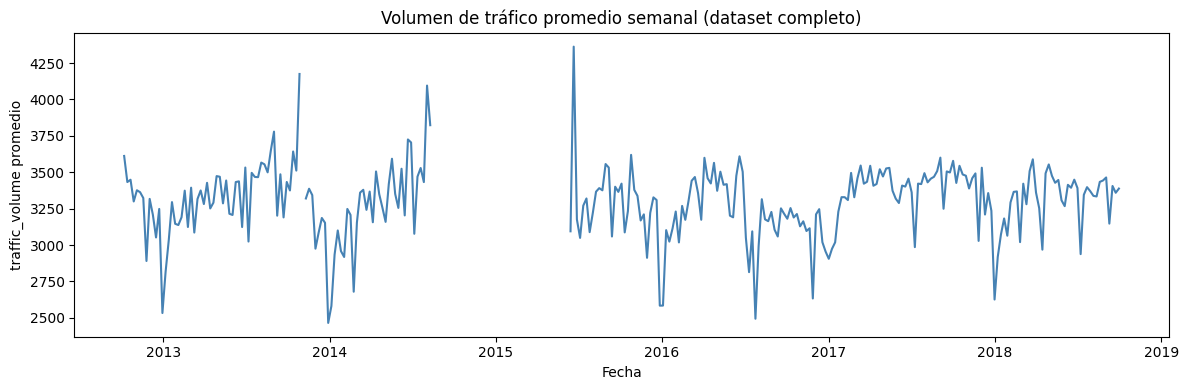

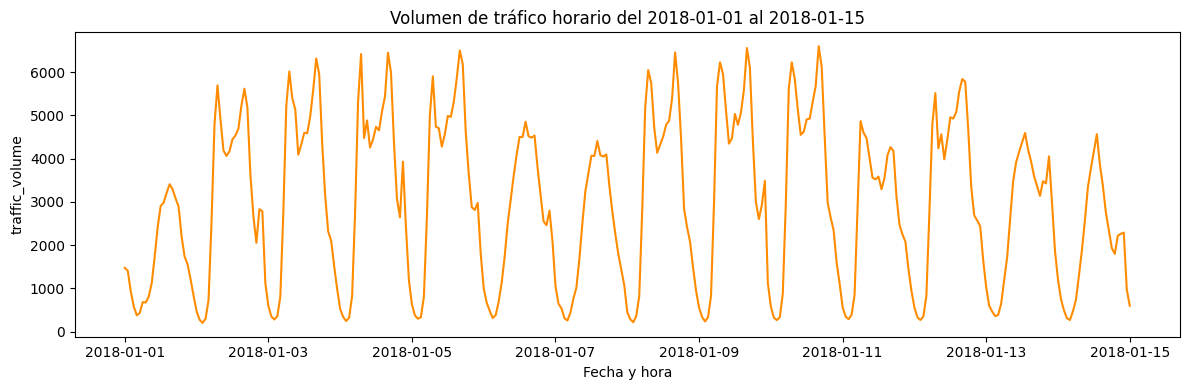

In [10]:
# Vista general agregada por semana para evitar una gráfica ilegible
serie_semanal = datos.set_index("date_time")["traffic_volume"].resample("W").mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie_semanal.index, serie_semanal.values, color="steelblue")
ax.set_title("Volumen de tráfico promedio semanal (dataset completo)")
ax.set_xlabel("Fecha")
ax.set_ylabel("traffic_volume promedio")
plt.tight_layout()
plt.show()

# Ventana corta de dos semanas en resolución horaria
ventana_inicio = pd.Timestamp("2018-01-01")
ventana_fin = ventana_inicio + pd.Timedelta(days=14)
serie_horaria = datos.set_index("date_time")["traffic_volume"]
ventana = serie_horaria.loc[ventana_inicio:ventana_fin]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ventana.index, ventana.values, color="darkorange")
ax.set_title(f"Volumen de tráfico horario del {ventana_inicio.date()} al {ventana_fin.date()}")
ax.set_xlabel("Fecha y hora")
ax.set_ylabel("traffic_volume")
plt.tight_layout()
plt.show()


### Patrones horarios y horas pico

Se calcula el volumen promedio y mediano de tráfico por hora del día, sin asumir de antemano cuáles son las horas pico: se identifican directamente a partir de los resultados.

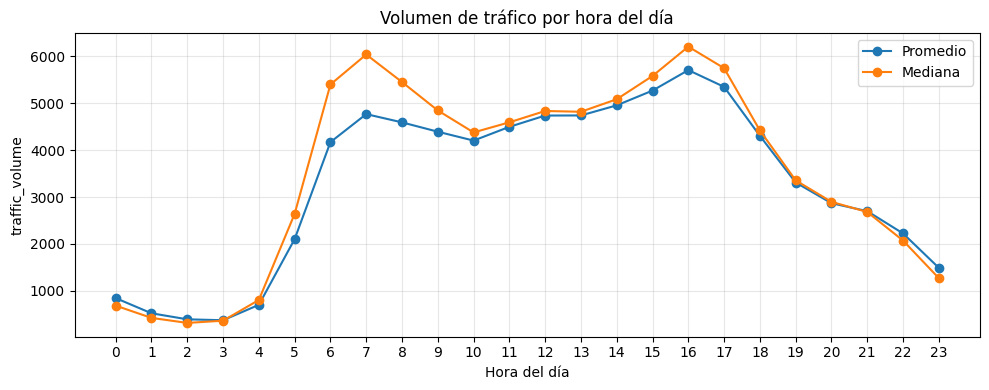

Las 5 horas con mayor volumen promedio:
hora
16    5708.614528
17    5350.830529
15    5271.737823
14    4957.022982
7     4769.831340
Name: mean, dtype: float64


In [11]:
datos["hora"] = datos["date_time"].dt.hour

volumen_por_hora = datos.groupby("hora")["traffic_volume"].agg(["mean", "median"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(volumen_por_hora.index, volumen_por_hora["mean"], marker="o", label="Promedio")
ax.plot(volumen_por_hora.index, volumen_por_hora["median"], marker="o", label="Mediana")
ax.set_title("Volumen de tráfico por hora del día")
ax.set_xlabel("Hora del día")
ax.set_ylabel("traffic_volume")
ax.set_xticks(range(0, 24))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

horas_pico = volumen_por_hora["mean"].sort_values(ascending=False).head(5)
print("Las 5 horas con mayor volumen promedio:")
print(horas_pico)


### Patrones por día de la semana

Se calcula el volumen promedio de tráfico para cada día de la semana, manteniendo el orden natural de lunes a domingo, y adicionalmente un mapa hora × día para visualizar la interacción entre ambos patrones.

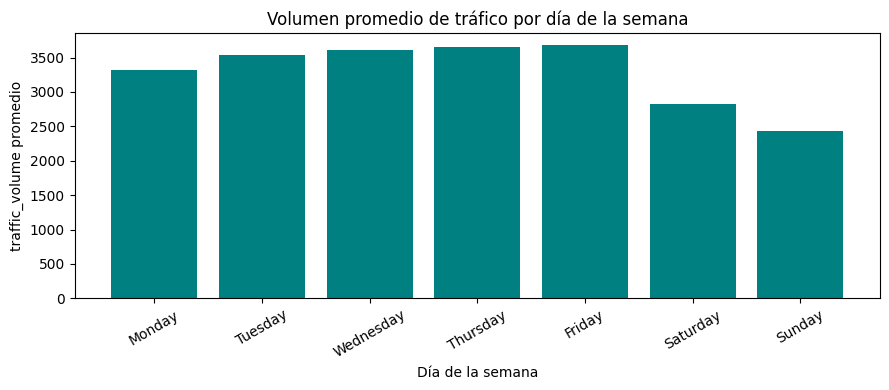

dia_semana
Monday       3313.560614
Tuesday      3534.717166
Wednesday    3608.276064
Thursday     3653.914611
Friday       3674.777608
Saturday     2822.564661
Sunday       2426.249484
Name: traffic_volume, dtype: float64

In [12]:
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
datos["dia_semana"] = datos["date_time"].dt.day_name()

volumen_por_dia = (
    datos.groupby("dia_semana")["traffic_volume"]
    .mean()
    .reindex(orden_dias)
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(volumen_por_dia.index, volumen_por_dia.values, color="teal")
ax.set_title("Volumen promedio de tráfico por día de la semana")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("traffic_volume promedio")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

volumen_por_dia


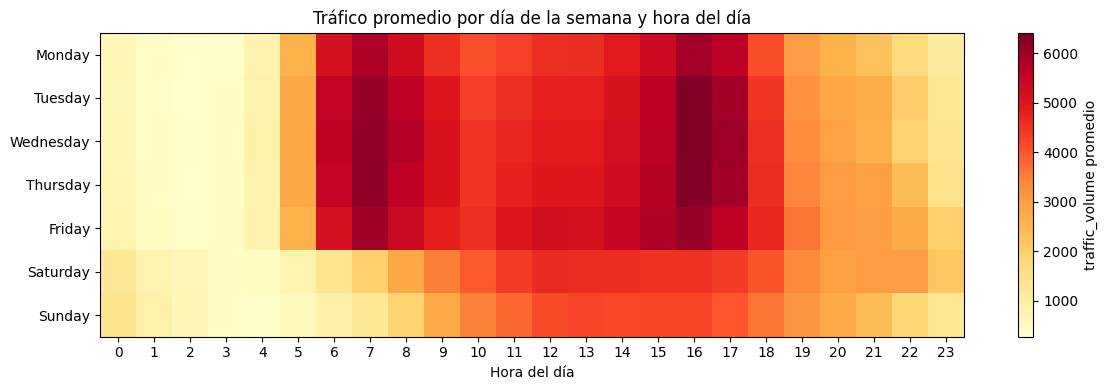

In [13]:
# Mapa hora x día de la semana para visualizar los patrones recurrentes de hora pico
tabla_hora_dia = datos.pivot_table(
    index="dia_semana", columns="hora", values="traffic_volume", aggfunc="mean"
).reindex(orden_dias)

fig, ax = plt.subplots(figsize=(12, 4))
mapa = ax.imshow(tabla_hora_dia.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(orden_dias)))
ax.set_yticklabels(orden_dias)
ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_xlabel("Hora del día")
ax.set_title("Tráfico promedio por día de la semana y hora del día")
fig.colorbar(mapa, ax=ax, label="traffic_volume promedio")
plt.tight_layout()
plt.show()


### Distribución del volumen de tráfico

Se examina la forma general de la distribución de `traffic_volume` mediante histograma, boxplot y percentiles. Los valores altos no se descartan por ser extremos: probablemente corresponden a horas pico reales.

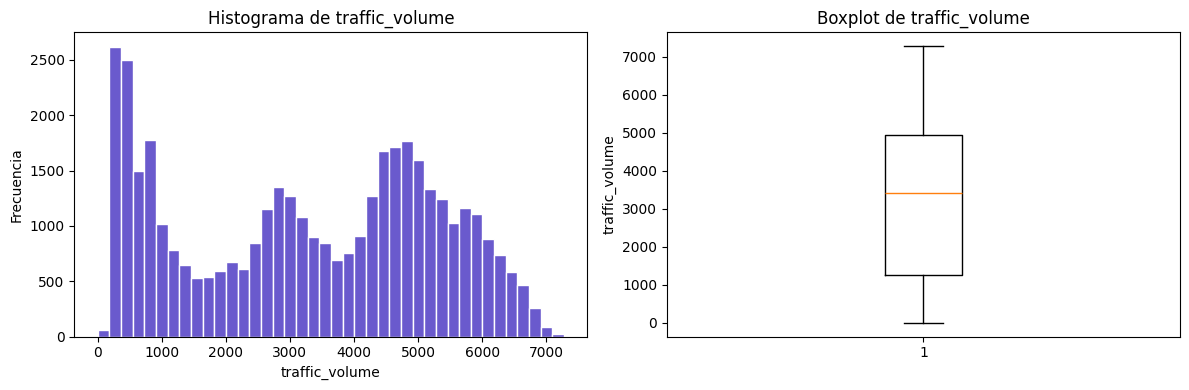

Percentiles de traffic_volume:
0.50    3427.0
0.75    4952.0
0.90    5835.0
0.95    6217.0
0.99    6713.0
Name: traffic_volume, dtype: float64


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(datos["traffic_volume"], bins=40, color="slateblue", edgecolor="white")
axes[0].set_title("Histograma de traffic_volume")
axes[0].set_xlabel("traffic_volume")
axes[0].set_ylabel("Frecuencia")

axes[1].boxplot(datos["traffic_volume"], vert=True)
axes[1].set_title("Boxplot de traffic_volume")
axes[1].set_ylabel("traffic_volume")

plt.tight_layout()
plt.show()

percentiles = datos["traffic_volume"].quantile([0.50, 0.75, 0.90, 0.95, 0.99])
print("Percentiles de traffic_volume:")
print(percentiles)


### Tendencia, periodicidad y autocorrelación

Se investiga la periodicidad diaria y semanal mediante una media móvil y la función de autocorrelación (ACF), calculada sobre una ventana continua reciente del dataset (no sobre la serie completa, que aún tiene huecos sin regularizar).

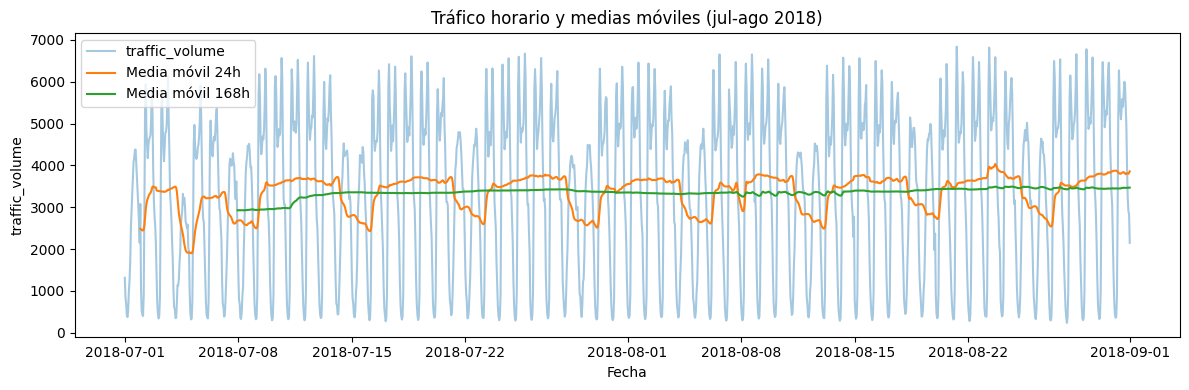

In [15]:
# Media móvil de 24h (ciclo diario) y de 168h (ciclo semanal) sobre una ventana continua reciente
serie_ventana = datos.set_index("date_time")["traffic_volume"].loc["2018-07-01":"2018-08-31"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie_ventana.index, serie_ventana.values, alpha=0.4, label="traffic_volume")
ax.plot(serie_ventana.index, serie_ventana.rolling(24).mean(), label="Media móvil 24h")
ax.plot(serie_ventana.index, serie_ventana.rolling(168).mean(), label="Media móvil 168h")
ax.set_title("Tráfico horario y medias móviles (jul-ago 2018)")
ax.set_xlabel("Fecha")
ax.set_ylabel("traffic_volume")
ax.legend()
plt.tight_layout()
plt.show()


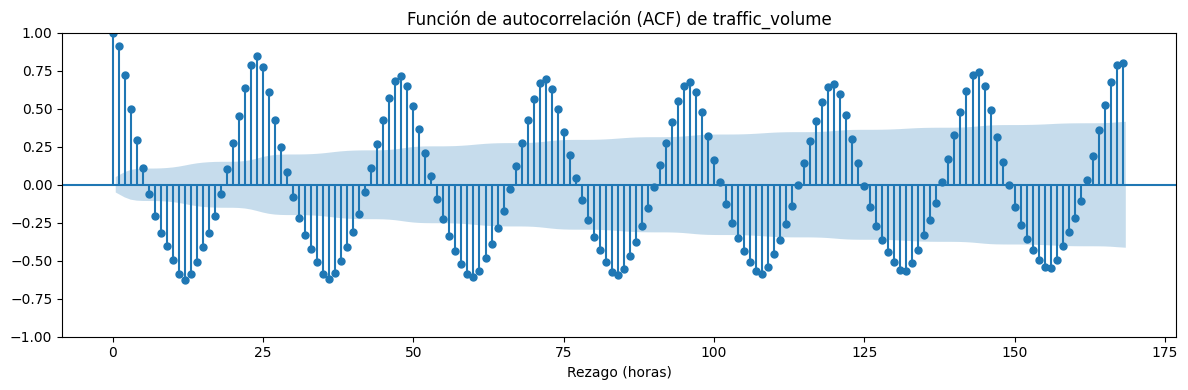

In [16]:
# Autocorrelación (ACF) hasta 7 días (168 horas) sobre la misma ventana continua
fig, ax = plt.subplots(figsize=(12, 4))
sm.graphics.tsa.plot_acf(serie_ventana.values, lags=168, ax=ax)
ax.set_title("Función de autocorrelación (ACF) de traffic_volume")
ax.set_xlabel("Rezago (horas)")
plt.tight_layout()
plt.show()


### Interpretación del análisis exploratorio

El análisis exploratorio confirma un patrón temporal claro y consistente en `traffic_volume`:

- **Ciclo diario bimodal en días laborales**: el volumen promedio más alto se concentra entre las **14:00 y 17:00** (máximo a las 16:00, ≈5.709 vehículos/hora), con un segundo pico más corto alrededor de las **07:00** (≈4.770). El tráfico es mínimo entre la medianoche y las 4:00 de la madrugada.
- **Diferencia clara entre días laborales y fin de semana**: de lunes a viernes el promedio se mantiene entre ≈3.300 y ≈3.675, mientras que sábado (≈2.823) y especialmente domingo (≈2.426) son notablemente más bajos. El mapa hora × día muestra que el patrón bimodal de horas pico prácticamente desaparece los fines de semana, reemplazado por una curva más suave centrada al mediodía.
- **Distribución**: el histograma de `traffic_volume` es bimodal (una moda baja cercana a cero, típica de la madrugada, y una moda alta hacia las horas de mayor congestión); la mediana es 3.427 y el percentil 90 se ubica en 5.835. No se observan valores atípicos que deban excluirse: los valores más altos corresponden a horas pico reales.
- **Periodicidad**: la media móvil de 24 horas confirma el ciclo diario, y la de 168 horas suaviza la variación semanal. El gráfico ACF muestra picos de autocorrelación positiva marcados cada 24 horas (y sus múltiplos), evidenciando una fuerte estacionalidad diaria, con una autocorrelación semanal más débil.
- El hueco histórico identificado previamente (ago-2014 a jun-2015) refuerza la necesidad de restringir el modelado a un período denso y continuo, que se selecciona en la siguiente sección.

## Preparación de la serie temporal para modelado

### Selección del período de modelado

Para ARIMA y LSTM se usa por defecto el **período denso** indicado en el SPEC:

```text
2017-01-01 00:00:00  a  2018-09-30 23:00:00
```

Este rango contiene aproximadamente 15.312 posiciones horarias esperadas, de las cuales solo faltan alrededor de 66 (cobertura superior al 99,5 %), y evita interpolar el gran hueco histórico detectado en años anteriores.

In [17]:
INICIO_MODELADO = pd.Timestamp("2017-01-01 00:00:00")
FIN_MODELADO = pd.Timestamp("2018-09-30 23:00:00")

periodo_denso = datos.set_index("date_time").loc[INICIO_MODELADO:FIN_MODELADO, ["traffic_volume"]]

indice_horas_periodo = pd.date_range(INICIO_MODELADO, FIN_MODELADO, freq="h")
horas_esperadas_periodo = len(indice_horas_periodo)
horas_observadas_periodo = periodo_denso.index.nunique()
horas_faltantes_periodo = horas_esperadas_periodo - horas_observadas_periodo

print(f"Horas esperadas en el período denso: {horas_esperadas_periodo}")
print(f"Horas observadas: {horas_observadas_periodo}")
print(f"Horas faltantes: {horas_faltantes_periodo}")
print(f"Cobertura: {horas_observadas_periodo / horas_esperadas_periodo:.4%}")


Horas esperadas en el período denso: 15312
Horas observadas: 15246
Horas faltantes: 66
Cobertura: 99.5690%


### División cronológica de entrenamiento, validación y prueba

Primero se regulariza la serie del período denso a frecuencia horaria exacta con `asfreq("h")`, conservando una máscara `is_observed` que distingue los valores realmente medidos de los que quedarán como huecos. Después se aplica la división cronológica recomendada por el SPEC (nunca aleatoria):

| Conjunto | Rango |
|---|---|
| Train | 2017-01-01 00:00 a 2018-03-31 23:00 |
| Validation | 2018-04-01 00:00 a 2018-06-30 23:00 |
| Test | 2018-07-01 00:00 a 2018-09-30 23:00 |

In [18]:
# Regularizar a frecuencia horaria exacta y conservar la máscara de valores observados
serie_regular = periodo_denso.asfreq("h")
serie_regular["is_observed"] = serie_regular["traffic_volume"].notna()

print(f"Filas tras regularizar: {serie_regular.shape[0]}")
print(f"Valores observados: {serie_regular['is_observed'].sum()}")
print(f"Valores a imputar: {(~serie_regular['is_observed']).sum()}")

# División cronológica: nunca aleatoria
FIN_TRAIN = pd.Timestamp("2018-03-31 23:00:00")
FIN_VALIDACION = pd.Timestamp("2018-06-30 23:00:00")

entrenamiento = serie_regular.loc[:FIN_TRAIN].copy()
validacion = serie_regular.loc[FIN_TRAIN + pd.Timedelta(hours=1):FIN_VALIDACION].copy()
prueba = serie_regular.loc[FIN_VALIDACION + pd.Timedelta(hours=1):].copy()

print(f"\nTrain      : {entrenamiento.index.min()} a {entrenamiento.index.max()}  ({len(entrenamiento)} horas)")
print(f"Validation : {validacion.index.min()} a {validacion.index.max()}  ({len(validacion)} horas)")
print(f"Test       : {prueba.index.min()} a {prueba.index.max()}  ({len(prueba)} horas)")

assert len(entrenamiento) + len(validacion) + len(prueba) == len(serie_regular), "Los splits no cubren toda la serie regularizada"
assert entrenamiento.index.max() < validacion.index.min(), "Train se traslapa con Validation"
assert validacion.index.max() < prueba.index.min(), "Validation se traslapa con Test"


Filas tras regularizar: 15312
Valores observados: 15246
Valores a imputar: 66

Train      : 2017-01-01 00:00:00 a 2018-03-31 23:00:00  (10920 horas)
Validation : 2018-04-01 00:00:00 a 2018-06-30 23:00:00  (2184 horas)
Test       : 2018-07-01 00:00:00 a 2018-09-30 23:00:00  (2208 horas)


#### Imputación sin fuga de información

La tabla de medianas de imputación se calcula **únicamente con los valores observados de Train** (agrupando por día de la semana y hora del día), y se aplica después a Train, Validation y Test. Como fallback, si alguna combinación día-hora no tiene mediana disponible en Train, se usa la mediana global del Train observado. Los puntos imputados conservan `is_observed=False` para poder excluirlos de las métricas finales.

In [19]:
# Tabla de medianas calculada SOLO con Train observado (día de la semana + hora)
train_observado = entrenamiento.loc[entrenamiento["is_observed"]].copy()
train_observado["dia_semana"] = train_observado.index.day_name()
train_observado["hora"] = train_observado.index.hour

medianas_dia_hora = (
    train_observado.groupby(["dia_semana", "hora"])["traffic_volume"].median()
)
mediana_global_train = train_observado["traffic_volume"].median()

print(f"Combinaciones día-hora con mediana calculada: {medianas_dia_hora.shape[0]} (esperado 7 x 24 = 168)")
print(f"Mediana global de Train (fallback): {mediana_global_train}")


def imputar_con_medianas(df):
    """Imputa traffic_volume usando la tabla de medianas día-hora de Train, sin usar información futura."""
    df = df.copy()
    dia_semana = df.index.day_name()
    hora = df.index.hour
    valores_imputados = pd.Series(
        [medianas_dia_hora.get((d, h), mediana_global_train) for d, h in zip(dia_semana, hora)],
        index=df.index,
    )
    df["traffic_volume"] = df["traffic_volume"].where(df["is_observed"], valores_imputados)
    return df


entrenamiento = imputar_con_medianas(entrenamiento)
validacion = imputar_con_medianas(validacion)
prueba = imputar_con_medianas(prueba)

assert entrenamiento["traffic_volume"].isna().sum() == 0
assert validacion["traffic_volume"].isna().sum() == 0
assert prueba["traffic_volume"].isna().sum() == 0
print("\nImputación completada. Sin valores nulos restantes en Train/Validation/Test.")


Combinaciones día-hora con mediana calculada: 168 (esperado 7 x 24 = 168)
Mediana global de Train (fallback): 3558.0

Imputación completada. Sin valores nulos restantes en Train/Validation/Test.


La regularización a frecuencia horaria del período denso (2017-01-01 a 2018-09-30) generó **15.312** posiciones, de las cuales **66** quedaron marcadas como `is_observed=False` (0,43 % del período). La división cronológica produjo **10.920** horas de Train, **2.184** de Validation y **2.208** de Test, sin traslape y sin usar `shuffle`. La tabla de medianas por día de la semana y hora, calculada exclusivamente con el Train observado, cubrió las **168** combinaciones posibles, por lo que no fue necesario recurrir al fallback de mediana global. Los 66 valores imputados quedan señalados por `is_observed`, de modo que las métricas de evaluación de los modelos puedan calcularse únicamente sobre targets originalmente observados.

### Modelo base de referencia

Antes de entrenar ARIMA se define un **baseline temporal** simple, que no usa ningún modelo estadístico: solo repite el valor observado 24 horas antes (ciclo diario) y 168 horas antes (ciclo semanal). Este baseline se calcula sobre la serie continua e imputada (Train + Validation + Test, ya regularizada), por lo que únicamente usa historial pasado real y nunca información futura. Las métricas (MAE, MSE, RMSE) se calculan solo sobre las horas de Test que fueron **originalmente observadas** (`is_observed=True`), para no premiar ni penalizar al modelo por los huecos imputados.

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# Serie continua e imputada (Train + Validation + Test) usada como historial para el baseline y para ARIMA
serie_completa = pd.concat([entrenamiento, validacion, prueba]).sort_index()
assert serie_completa.index.is_monotonic_increasing
assert serie_completa["traffic_volume"].isna().sum() == 0


def calcular_metricas(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    return mae, mse, rmse


baseline_24 = serie_completa["traffic_volume"].shift(24)
baseline_168 = serie_completa["traffic_volume"].shift(168)

idx_test = prueba.index
mascara_test_observado = serie_completa.loc[idx_test, "is_observed"]
y_test_real = serie_completa.loc[idx_test, "traffic_volume"][mascara_test_observado]

mae_24, mse_24, rmse_24 = calcular_metricas(y_test_real, baseline_24.loc[idx_test][mascara_test_observado])
mae_168, mse_168, rmse_168 = calcular_metricas(y_test_real, baseline_168.loc[idx_test][mascara_test_observado])

print(f"Horas de Test evaluadas (originalmente observadas): {mascara_test_observado.sum()} de {len(idx_test)}")
print(f"\nBaseline t-24  -> MAE={mae_24:.2f}  MSE={mse_24:.2f}  RMSE={rmse_24:.2f}")
print(f"Baseline t-168 -> MAE={mae_168:.2f}  MSE={mse_168:.2f}  RMSE={rmse_168:.2f}")


Horas de Test evaluadas (originalmente observadas): 2204 de 2208

Baseline t-24  -> MAE=508.08  MSE=938204.24  RMSE=968.61
Baseline t-168 -> MAE=261.89  MSE=305764.96  RMSE=552.96


## Predicción con ARIMA

Se modela exclusivamente la variable univariada `traffic_volume`. El entrenamiento del modelo ARIMA se realiza **solo con Train**; Validation se usa únicamente para comparar configuraciones `(p,d,q)` (nunca Test), y Test se reserva exclusivamente para la evaluación final walk-forward. No se sustituye ARIMA por SARIMA, Prophet ni ningún otro algoritmo; SARIMA se menciona más adelante solo como trabajo futuro.

### Análisis de estacionariedad

Se grafica la serie de Train, se aplica la prueba de Dickey-Fuller aumentada (ADF) sobre `traffic_volume` y se examinan sus funciones de autocorrelación (ACF) y autocorrelación parcial (PACF), para decidir de forma razonada si se necesita diferenciar la serie (`d`) y para acotar candidatos de `p` y `q`.

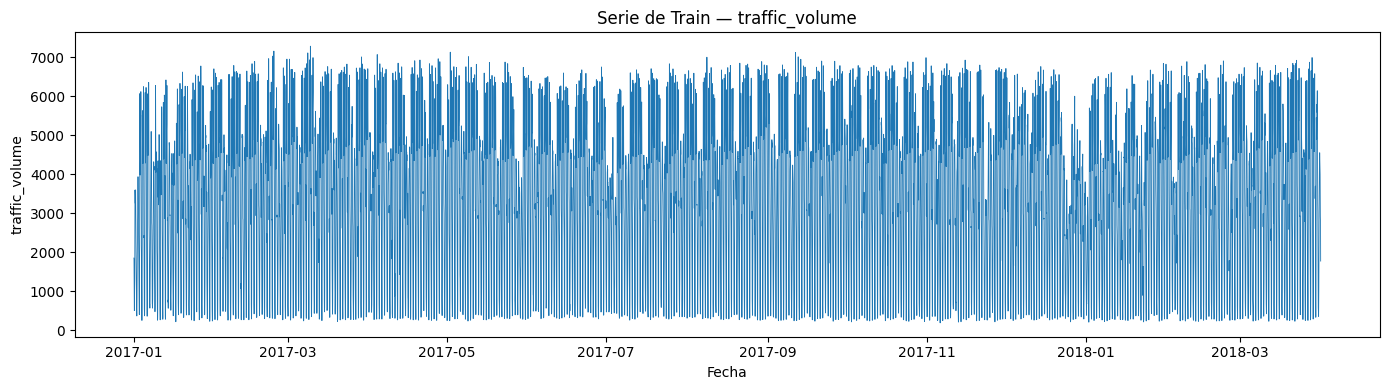

Prueba ADF sobre Train (serie sin diferenciar):
  Estadístico ADF : -12.1287
  p-valor         : 0.000000
  Valores críticos: {'1%': -3.430951180468926, '5%': -2.8618056883724874, '10%': -2.5669114207886166}
  ¿Estacionaria al 5%? Sí


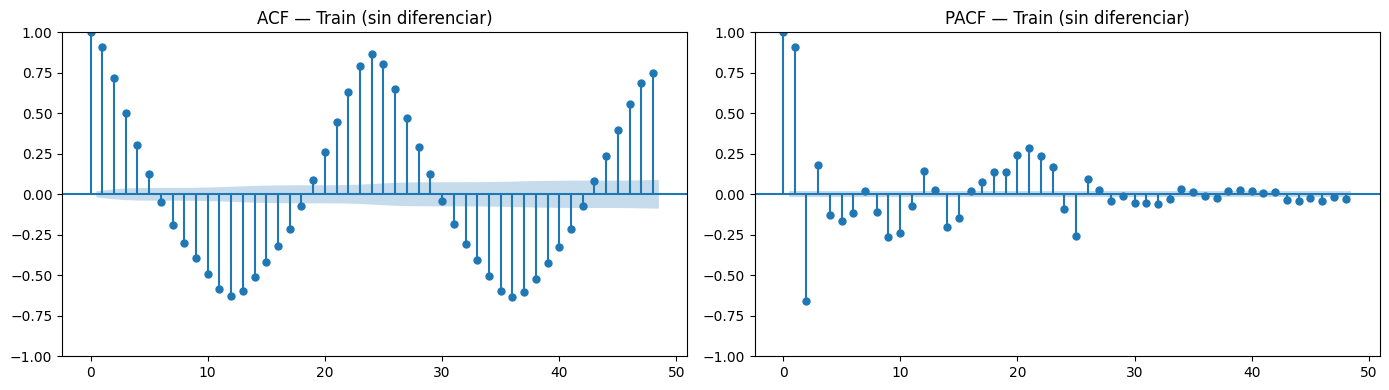

In [21]:
serie_train = entrenamiento["traffic_volume"]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(serie_train.index, serie_train.values, linewidth=0.6)
ax.set_title("Serie de Train — traffic_volume")
ax.set_xlabel("Fecha")
ax.set_ylabel("traffic_volume")
plt.tight_layout()
plt.show()

resultado_adf = adfuller(serie_train)
print("Prueba ADF sobre Train (serie sin diferenciar):")
print(f"  Estadístico ADF : {resultado_adf[0]:.4f}")
print(f"  p-valor         : {resultado_adf[1]:.6f}")
print(f"  Valores críticos: {resultado_adf[4]}")
es_estacionaria = resultado_adf[1] < 0.05
print(f"  ¿Estacionaria al 5%? {'Sí' if es_estacionaria else 'No'}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(serie_train, lags=48, ax=axes[0])
axes[0].set_title("ACF — Train (sin diferenciar)")
plot_pacf(serie_train, lags=48, ax=axes[1], method="ywm")
axes[1].set_title("PACF — Train (sin diferenciar)")
plt.tight_layout()
plt.show()


**Lectura de los resultados:**

- **ADF**: estadístico = -12,13, p-valor ≈ 0,000000, muy por debajo de todos los valores críticos (1 %, 5 %, 10 %). Se **rechaza la hipótesis nula de raíz unitaria**: la serie de Train ya es estacionaria en el sentido de la prueba ADF, por lo que **no se necesita diferenciar** → `d = 0`.
- **ACF**: decae de forma oscilante (no corta abruptamente), con máximos locales cada ~24 horas, reflejo directo del ciclo diario visible en el EDA. Este patrón ondulado es típico de procesos con componente autorregresivo y no de un proceso puramente de medias móviles.
- **PACF**: presenta picos claramente significativos en los primeros rezagos (particularmente `lag 1` y `lag 2`, este último con correlación parcial fuertemente negativa) y luego cae a valores mucho más pequeños, con repuntes menores alrededor de `lag ≈ 20-25` (eco del ciclo diario que un ARIMA no estacional no puede modelar explícitamente).

Con base en esta lectura se acotan los candidatos: `d = 0` (confirmado por ADF); `p ∈ {1, 2, 3}` (los rezagos con PACF significativo); `q ∈ {0, 1}` (para permitir un pequeño componente de medias móviles sin ampliar demasiado la búsqueda). Se documenta explícitamente que, dado que la actividad exige ARIMA (no SARIMA), la periodicidad diaria de 24 horas visible en la ACF **no se modela de forma estacional**, lo cual es una limitación esperada y se discute en la interpretación final.

### Selección de parámetros del modelo ARIMA

- **`p` (orden autorregresivo, AR)**: número de rezagos pasados de `traffic_volume` que se usan directamente para predecir el valor actual. Se acota con la PACF.
- **`d` (orden de diferenciación)**: número de veces que hay que diferenciar la serie para volverla estacionaria. La prueba ADF ya confirmó que Train es estacionaria, por lo que `d = 0`.
- **`q` (orden de medias móviles, MA)**: número de rezagos pasados del error de predicción que se usan para corregir la predicción actual. Se acota con la ACF.

Siguiendo el SPEC, **no se realiza una búsqueda gigantesca**: se evalúa un conjunto pequeño y razonado de configuraciones `(p, 0, q)` acotadas por la lectura de ACF/PACF. Cada modelo se entrena **solo con Train** y se compara con dos criterios: el **AIC** (ajuste dentro de Train) y el **RMSE sobre Validation** (nunca Test), pronosticando de forma estática los mismos pasos que dura Validation.

In [22]:
# Conjunto pequeño y razonado de candidatos (d=0 confirmado por ADF; p y q acotados por PACF/ACF)
candidatos_pdq = [(1, 0, 0), (2, 0, 0), (3, 0, 0), (2, 0, 1), (3, 0, 1)]

HORIZONTE_BLOQUE = 24  # se re-ancla el estado del modelo cada 24 h con observaciones reales (walk-forward por bloques)


def walk_forward_bloques(ajuste_inicial, serie_objetivo, horizonte=HORIZONTE_BLOQUE):
    """Pronostica serie_objetivo por bloques de `horizonte` pasos, incorporando después cada bloque real
    (sin refit completo) para el siguiente bloque. Nunca usa información futura."""
    predicciones = []
    ajuste_actual = ajuste_inicial
    valores = serie_objetivo.values
    n = len(valores)
    for inicio in range(0, n, horizonte):
        fin = min(inicio + horizonte, n)
        pasos = fin - inicio
        pronostico_bloque = ajuste_actual.forecast(steps=pasos)
        predicciones.append(pronostico_bloque.values)
        ajuste_actual = ajuste_actual.append(valores[inicio:fin], refit=False)
    return pd.Series(np.concatenate(predicciones), index=serie_objetivo.index)


y_validacion_real = validacion["traffic_volume"]
mascara_validacion_obs = validacion["is_observed"]

resultados_seleccion = []
for orden in candidatos_pdq:
    modelo = ARIMA(serie_train, order=orden, enforce_stationarity=False, enforce_invertibility=False)
    ajuste = modelo.fit()
    pronostico_validacion = walk_forward_bloques(ajuste, y_validacion_real)
    mae_v, mse_v, rmse_v = calcular_metricas(
        y_validacion_real[mascara_validacion_obs], pronostico_validacion[mascara_validacion_obs]
    )
    resultados_seleccion.append({"orden": orden, "AIC": ajuste.aic, "MAE_val": mae_v, "MSE_val": mse_v, "RMSE_val": rmse_v})
    print(f"ARIMA{orden} -> AIC={ajuste.aic:.1f}  MAE_val={mae_v:.2f}  RMSE_val={rmse_v:.2f}")

tabla_seleccion = pd.DataFrame(resultados_seleccion).sort_values("RMSE_val").reset_index(drop=True)
print("\nRanking por RMSE en Validation (walk-forward por bloques de 24h):")
print(tabla_seleccion)

ORDEN_ARIMA = tuple(tabla_seleccion.loc[0, "orden"])
print(f"\nConfiguración ARIMA seleccionada: {ORDEN_ARIMA}")


ARIMA(1, 0, 0) -> AIC=177339.7  MAE_val=1729.79  RMSE_val=2031.41
ARIMA(2, 0, 0) -> AIC=171033.1  MAE_val=1440.99  RMSE_val=1685.11
ARIMA(3, 0, 0) -> AIC=170640.3  MAE_val=1487.06  RMSE_val=1734.27
ARIMA(2, 0, 1) -> AIC=170580.4  MAE_val=1474.40  RMSE_val=1720.02
ARIMA(3, 0, 1) -> AIC=170566.0  MAE_val=1475.04  RMSE_val=1720.74

Ranking por RMSE en Validation (walk-forward por bloques de 24h):
       orden            AIC      MAE_val       MSE_val     RMSE_val
0  (2, 0, 0)  171033.105471  1440.992937  2.839579e+06  1685.105147
1  (2, 0, 1)  170580.399994  1474.404819  2.958467e+06  1720.019510
2  (3, 0, 1)  170565.957115  1475.040714  2.960930e+06  1720.735419
3  (3, 0, 0)  170640.286760  1487.060419  3.007690e+06  1734.269347
4  (1, 0, 0)  177339.684400  1729.789969  4.126607e+06  2031.405066

Configuración ARIMA seleccionada: (2, 0, 0)


**Configuración ganadora: ARIMA(2, 0, 0)**. Es el mejor tanto en AIC (segundo más bajo, prácticamente empatado con las variantes con `q=1`) como, sobre todo, en RMSE de Validation (1.685,1), superando claramente a ARIMA(1,0,0) (2.031,4) y a las variantes con `q=1`, que no mejoran el error pese a tener AIC ligeramente menor — indicio de que agregar el término MA no aporta valor predictivo real y solo ajusta mejor dentro de Train (sobreajuste leve). La selección se basó en Validation, nunca en Test, cumpliendo la restricción del SPEC.

### Evaluación del modelo ARIMA

El modelo final `ARIMA(2, 0, 0)` se entrena con Train **y luego se le incorpora Validation** (con `append(refit=False)`, sin reajustar parámetros) para llegar al inicio de Test con el historial más reciente posible, sin volver a estimar coeficientes con datos de Validation. Sobre Test se aplica un protocolo estrictamente **one-step-ahead / walk-forward**: en cada hora se pronostica un solo paso hacia adelante usando únicamente el historial disponible hasta ese momento, y **después** se incorpora la observación real (sin refit) antes de pronosticar la siguiente hora. Nunca se usa información futura. Las métricas se calculan solo sobre las horas de Test originalmente observadas.

In [23]:
# Modelo final: se entrena con Train y se extiende con Validation (sin refit) antes de evaluar en Test
modelo_final = ARIMA(serie_train, order=ORDEN_ARIMA, enforce_stationarity=False, enforce_invertibility=False)
ajuste_final = modelo_final.fit()
ajuste_final = ajuste_final.append(validacion["traffic_volume"].values, refit=False)

# Walk-forward one-step-ahead sobre Test: pronostica 1 paso, luego incorpora el valor real (sin refit)
predicciones_test = []
ajuste_actual = ajuste_final
valores_test = prueba["traffic_volume"].values
for i in range(len(valores_test)):
    pred_un_paso = ajuste_actual.forecast(steps=1).iloc[0]
    predicciones_test.append(pred_un_paso)
    ajuste_actual = ajuste_actual.append([valores_test[i]], refit=False)

y_pred_arima = pd.Series(predicciones_test, index=prueba.index)
y_test_arima = prueba["traffic_volume"]

mascara_test_obs = prueba["is_observed"]
mae_arima, mse_arima, rmse_arima = calcular_metricas(
    y_test_arima[mascara_test_obs], y_pred_arima[mascara_test_obs]
)

print(f"ARIMA{ORDEN_ARIMA} — evaluación walk-forward one-step-ahead sobre Test")
print(f"MAE  = {mae_arima:.2f}")
print(f"MSE  = {mse_arima:.2f}")
print(f"RMSE = {rmse_arima:.2f}")


ARIMA(2, 0, 0) — evaluación walk-forward one-step-ahead sobre Test
MAE  = 418.24
MSE  = 301142.57
RMSE = 548.76


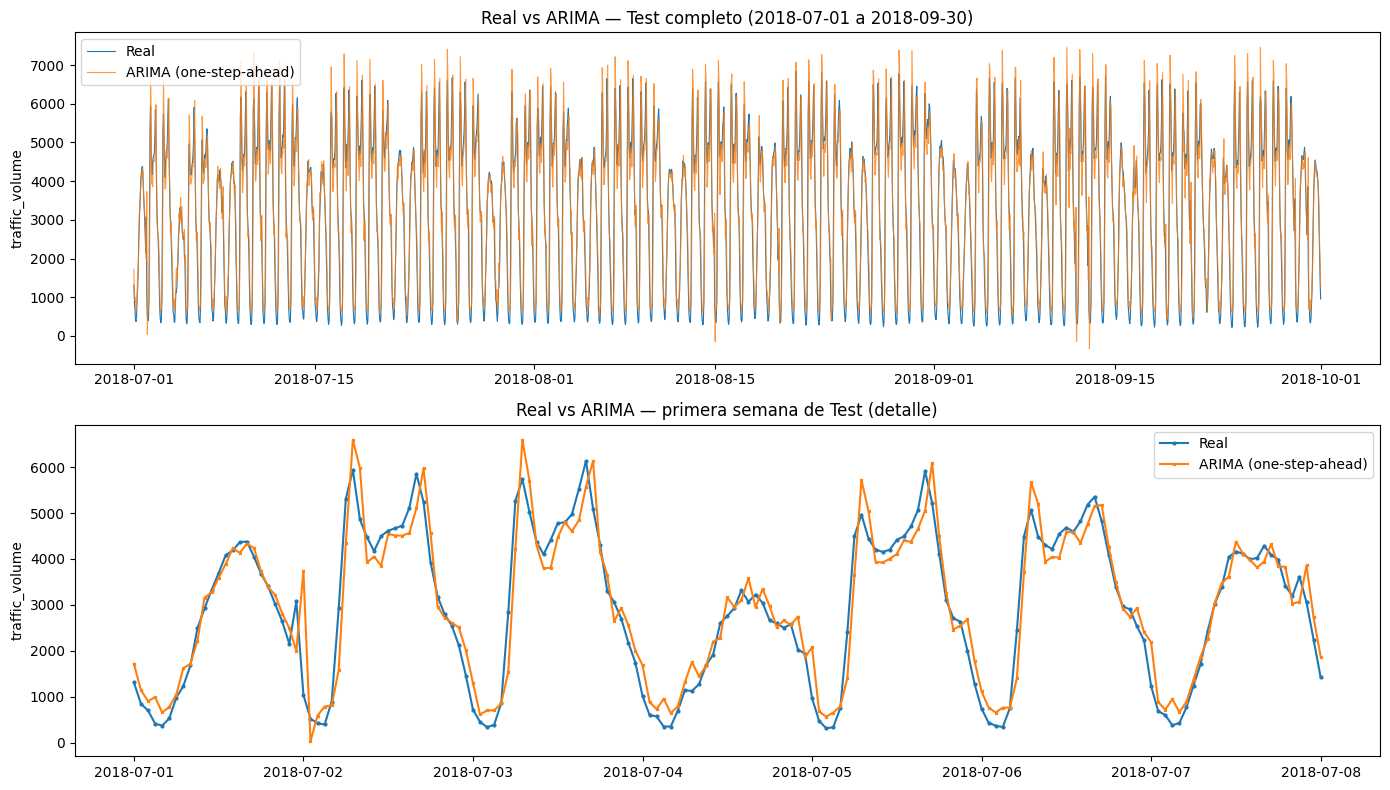

In [25]:
# Gráficas Real vs ARIMA: todo Test y una semana de detalle
def graficar_serie_vs_modelos(ax, series, titulo, ylabel="traffic_volume"):
    """Grafica sobre `ax` una lista de (nombre, serie, kwargs_de_plot) ya alineadas en el tiempo."""
    for nombre, serie, kwargs in series:
        ax.plot(serie.index, serie.values, label=nombre, **kwargs)
    ax.set_title(titulo)
    ax.set_ylabel(ylabel)
    ax.legend()


fig, axes = plt.subplots(2, 1, figsize=(14, 8))

graficar_serie_vs_modelos(
    axes[0],
    [
        ("Real", y_test_arima, {"linewidth": 0.8}),
        ("ARIMA (one-step-ahead)", y_pred_arima, {"linewidth": 0.8, "alpha": 0.8}),
    ],
    "Real vs ARIMA — Test completo (2018-07-01 a 2018-09-30)",
)

semana_inicio, semana_fin = prueba.index[0], prueba.index[0] + pd.Timedelta(days=7)
graficar_serie_vs_modelos(
    axes[1],
    [
        ("Real", y_test_arima.loc[semana_inicio:semana_fin], {"marker": "o", "markersize": 2}),
        ("ARIMA (one-step-ahead)", y_pred_arima.loc[semana_inicio:semana_fin], {"marker": "x", "markersize": 2}),
    ],
    "Real vs ARIMA — primera semana de Test (detalle)",
)

plt.tight_layout()
plt.show()


### Interpretación de los resultados de ARIMA

**Comparación de métricas sobre Test (solo horas originalmente observadas):**

| Modelo | MAE | MSE | RMSE |
|---|---|---|---|
| Baseline t-24 | 508,08 | 938.204,24 | 968,61 |
| Baseline t-168 | 261,89 | 305.764,96 | 552,96 |
| **ARIMA(2,0,0) one-step-ahead** | **418,24** | **301.142,57** | **548,76** |

- El ARIMA(2,0,0) walk-forward **supera ligeramente al mejor baseline** (RMSE 548,76 vs 552,96 de t-168) y mejora ampliamente el baseline ingenuo t-24. Esto confirma que el modelo aprende una dinámica útil de corto plazo (un paso adelante), apoyada en el fuerte componente autorregresivo detectado en la PACF.
- Sin embargo, la ventaja frente al baseline t-168 es marginal (~0,8 % de RMSE): al ser un modelo **ARIMA no estacional**, no incorpora explícitamente el ciclo diario de 24 horas identificado en la ACF, y por eso la gráfica de detalle muestra que sus picos y valles diarios están ligeramente desfasados/sobreestimados respecto al patrón real, especialmente en las transiciones rápidas madrugada→hora pico.
- El buen desempeño del baseline t-168 (repetir el valor de la semana anterior) confirma cuantitativamente la fuerte estacionalidad semanal que ya se había observado en el EDA: para esta serie, "lo que pasó la semana pasada a esta hora" es casi tan buen predictor como un modelo ARIMA ajustado.
- Esta limitación es esperada y coherente con la restricción del SPEC de no sustituir ARIMA por un modelo estacional (SARIMA); se documenta aquí como posible mejora futura, sin implementarla en este trabajo.

**Evidencia de cumplimiento:**

- **RF-13 (Baseline)**: implementado con t-24 y t-168, métricas calculadas con la misma función que ARIMA, sin reemplazar a ARIMA/LSTM.
- **RF-14 (Preparación ARIMA)**: se usó exclusivamente `traffic_volume`; se graficó la serie de Train; se aplicó ADF (p≈0, estacionaria, `d=0`); se analizaron ACF y PACF; se explicó el significado de `p`, `d`, `q` y la razón de la selección final.
- **RF-15 (Selección del ARIMA)**: se usó `statsmodels.tsa.arima.model.ARIMA`; se evaluó un conjunto pequeño de 5 configuraciones (no una búsqueda gigantesca), acotadas por ACF/PACF; se usó AIC como criterio auxiliar y RMSE/MAE en Validation (nunca Test) como criterio de decisión; se documentó la configuración ganadora `(2,0,0)`; no se sustituyó ARIMA por SARIMA/Prophet/otro modelo.
- **RF-16 (Evaluación ARIMA)**: evaluación sobre Test con protocolo one-step-ahead/walk-forward (`append(refit=False)` para incorporar cada observación real sin reajustar coeficientes completos); se guardaron `y_test_arima` e `y_pred_arima` con timestamps alineados; se calcularon MAE, MSE y RMSE; se graficó Real vs ARIMA para todo Test y para una semana de detalle.

## Predicción con red neuronal LSTM

Al igual que en ARIMA, la única variable modelada es `traffic_volume`. Se usa el período denso ya regularizado e imputado (Train/Validation/Test cronológicos) para escalar los datos, construir secuencias temporales y entrenar una red LSTM con Keras/TensorFlow (entorno `tf-gpu`).

### Escalado y creación de secuencias

El `MinMaxScaler` se ajusta (`fit`) **únicamente con Train**, y ese mismo escalador ya ajustado se usa solo para `transform` en Train, Validation y Test — nunca se reajusta con Validation/Test ni con la serie completa. Las secuencias se generan **por separado dentro de cada conjunto** (Train, Validation, Test), sin que ninguna ventana cruce el límite entre conjuntos, para no mezclar temporalmente los tres splits. Se usa una ventana de **168 horas** (una semana completa), ya que el costo computacional es razonable con la longitud de Train disponible (10.920 horas).

In [26]:
from sklearn.preprocessing import MinMaxScaler

# Escalador ajustado SOLO con Train; se reutiliza (sin volver a ajustar) para Validation y Test
escalador = MinMaxScaler()
escalador.fit(entrenamiento[["traffic_volume"]])

train_escalado = escalador.transform(entrenamiento[["traffic_volume"]])
val_escalado = escalador.transform(validacion[["traffic_volume"]])
test_escalado = escalador.transform(prueba[["traffic_volume"]])

VENTANA_LSTM = 168  # una semana completa; costo computacional razonable dado el tamaño de Train


def create_sequences(array, ventana):
    """Construye secuencias (X, y) de longitud `ventana` sin cruzar límites externos al array recibido."""
    X, y = [], []
    for i in range(ventana, len(array)):
        X.append(array[i - ventana:i, 0])
        y.append(array[i, 0])
    X = np.array(X).reshape(-1, ventana, 1)
    y = np.array(y)
    return X, y


X_train, y_train = create_sequences(train_escalado, VENTANA_LSTM)
X_val, y_val = create_sequences(val_escalado, VENTANA_LSTM)
X_test, y_test = create_sequences(test_escalado, VENTANA_LSTM)

# Timestamps y máscara is_observed alineados con el target de cada secuencia (por separado en cada split)
timestamps_test_lstm = prueba.index[VENTANA_LSTM:]
mascara_test_lstm_obs = prueba["is_observed"].iloc[VENTANA_LSTM:].values

print(f"X_train: {X_train.shape}  y_train: {y_train.shape}")
print(f"X_val  : {X_val.shape}  y_val: {y_val.shape}")
print(f"X_test : {X_test.shape}  y_test: {y_test.shape}")
print(f"Timestamps de Test alineados: {len(timestamps_test_lstm)}  |  observados originalmente: {mascara_test_lstm_obs.sum()}")


X_train: (10752, 168, 1)  y_train: (10752,)
X_val  : (2016, 168, 1)  y_val: (2016,)
X_test : (2040, 168, 1)  y_test: (2040,)
Timestamps de Test alineados: 2040  |  observados originalmente: 2036


### Arquitectura de la red LSTM

Arquitectura: capa `Input` explícita → `LSTM(50, return_sequences=True)` → `LSTM(50)` → `Dense(25, relu)` → `Dense(1)`, compilada con `optimizer="adam"` y `loss="mse"`.

In [27]:
modelo_lstm = tf.keras.Sequential([
    tf.keras.Input(shape=(VENTANA_LSTM, 1)),
    tf.keras.layers.LSTM(50, return_sequences=True),
    tf.keras.layers.LSTM(50),
    tf.keras.layers.Dense(25, activation="relu"),
    tf.keras.layers.Dense(1),
])

modelo_lstm.compile(optimizer="adam", loss="mse")
modelo_lstm.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 168, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

### Entrenamiento de la LSTM

Se entrena con `validation_data=(X_val, y_val)`, `shuffle=False` (para no romper el orden cronológico de las secuencias), `batch_size=32`, un máximo de 50 épocas y `EarlyStopping` sobre `val_loss` que restaura los mejores pesos.

In [28]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = modelo_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=2,
)

print(f"\nÉpocas entrenadas: {len(history.history['loss'])}")
print(f"Mejor val_loss: {min(history.history['val_loss']):.6f}")


Epoch 1/50
336/336 - 21s - 63ms/step - loss: 0.0259 - val_loss: 0.0109
Epoch 2/50
336/336 - 17s - 50ms/step - loss: 0.0100 - val_loss: 0.0072
Epoch 3/50
336/336 - 18s - 53ms/step - loss: 0.0064 - val_loss: 0.0048
Epoch 4/50
336/336 - 17s - 51ms/step - loss: 0.0041 - val_loss: 0.0026
Epoch 5/50
336/336 - 18s - 53ms/step - loss: 0.0033 - val_loss: 0.0022
Epoch 6/50
336/336 - 17s - 51ms/step - loss: 0.0029 - val_loss: 0.0021
Epoch 7/50
336/336 - 18s - 53ms/step - loss: 0.0027 - val_loss: 0.0019
Epoch 8/50
336/336 - 18s - 55ms/step - loss: 0.0025 - val_loss: 0.0018
Epoch 9/50
336/336 - 17s - 51ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 10/50
336/336 - 18s - 54ms/step - loss: 0.0024 - val_loss: 0.0017
Epoch 11/50
336/336 - 18s - 53ms/step - loss: 0.0023 - val_loss: 0.0016
Epoch 12/50
336/336 - 18s - 55ms/step - loss: 0.0022 - val_loss: 0.0016
Epoch 13/50
336/336 - 17s - 51ms/step - loss: 0.0022 - val_loss: 0.0016
Epoch 14/50
336/336 - 17s - 52ms/step - loss: 0.0021 - val_loss: 0.0015
E

### Evaluación de la LSTM

Se grafican `loss` y `val_loss` por época para interpretar la convergencia del entrenamiento antes de evaluar sobre Test.

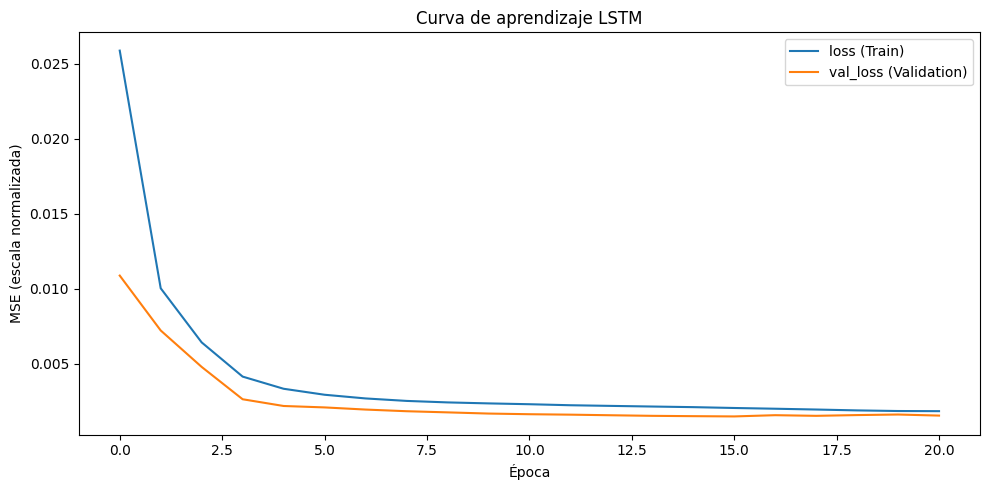

Época con mejor val_loss: 16 de 21 entrenadas


In [29]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history.history["loss"], label="loss (Train)")
ax.plot(history.history["val_loss"], label="val_loss (Validation)")
ax.set_xlabel("Época")
ax.set_ylabel("MSE (escala normalizada)")
ax.set_title("Curva de aprendizaje LSTM")
ax.legend()
plt.tight_layout()
plt.show()

epoca_mejor_val = int(np.argmin(history.history["val_loss"])) + 1
print(f"Época con mejor val_loss: {epoca_mejor_val} de {len(history.history['loss'])} entrenadas")


**Predicción sobre Test:** se genera `y_pred_lstm` con el modelo entrenado, se desnormaliza junto con `y_test` usando el mismo `escalador` (ajustado solo con Train), se alinean los timestamps de `prueba.index[VENTANA_LSTM:]` y se calculan MAE/MSE/RMSE excluyendo las horas que originalmente eran huecos imputados (`is_observed=False`).

In [30]:
pred_escalada_lstm = modelo_lstm.predict(X_test, verbose=0)

y_pred_lstm = escalador.inverse_transform(pred_escalada_lstm).ravel()
y_test_lstm = escalador.inverse_transform(y_test.reshape(-1, 1)).ravel()

y_pred_lstm = pd.Series(y_pred_lstm, index=timestamps_test_lstm)
y_test_lstm = pd.Series(y_test_lstm, index=timestamps_test_lstm)

assert (y_pred_lstm.index == timestamps_test_lstm).all()
assert (y_test_lstm.index == prueba.index[VENTANA_LSTM:]).all()

mae_lstm, mse_lstm, rmse_lstm = calcular_metricas(
    y_test_lstm[mascara_test_lstm_obs], y_pred_lstm[mascara_test_lstm_obs]
)

print(f"Horas de Test evaluadas (originalmente observadas): {mascara_test_lstm_obs.sum()} de {len(timestamps_test_lstm)}")
print(f"\nLSTM — evaluación sobre Test")
print(f"MAE  = {mae_lstm:.2f}")
print(f"MSE  = {mse_lstm:.2f}")
print(f"RMSE = {rmse_lstm:.2f}")


Horas de Test evaluadas (originalmente observadas): 2036 de 2040

LSTM — evaluación sobre Test
MAE  = 184.35
MSE  = 69161.39
RMSE = 262.99


### Interpretación de los resultados de la LSTM

**Verificación de shapes:** `X_train (10752, 168, 1)`, `X_val (2016, 168, 1)`, `X_test (2040, 168, 1)`; cada secuencia usa 168 horas pasadas para predecir la siguiente. Los timestamps de Test quedaron alineados en `prueba.index[168:]` (2.040 posiciones), de las cuales 2.036 eran horas originalmente observadas (4 imputadas fueron excluidas de las métricas).

**Verificación de ausencia de data leakage:**
- El `MinMaxScaler` se ajustó (`fit`) únicamente con `entrenamiento[["traffic_volume"]]`; Validation y Test solo usaron `transform` con ese mismo escalador.
- Las secuencias se generaron por separado dentro de cada conjunto (`create_sequences` aplicada individualmente a Train, Validation y Test), así que ninguna ventana de entrada contiene datos de otro split.
- El entrenamiento usó `shuffle=False`, preservando el orden cronológico, y `validation_data` fue exclusivamente Validation (nunca Test).
- Test solo se usó al final, una única vez, para la evaluación reportada aquí.

**Interpretación de `loss` vs `val_loss`:** ambas curvas descienden de forma consistente y `val_loss` se mantiene sistemáticamente igual o por debajo de `loss`, sin repuntar antes de que `EarlyStopping` detuviera el entrenamiento (época 21, mejor peso en la época 16, `val_loss≈0,001485`). No hay evidencia de sobreajuste: el modelo generaliza a Validation al menos tan bien como a Train, y la convergencia es estable desde aproximadamente la época 8-10.

**Métricas reales sobre Test (excluyendo huecos imputados):**

| Modelo | MAE | MSE | RMSE |
|---|---|---|---|
| Baseline t-168 | 261,89 | 305.764,96 | 552,96 |
| ARIMA(2,0,0) one-step-ahead | 418,24 | 301.142,57 | 548,76 |
| **LSTM (ventana 168h)** | **184,35** | **69.161,39** | **262,99** |

La LSTM reduce el RMSE en más de un 50 % frente a ARIMA y frente al mejor baseline, lo cual es coherente con lo esperado: al recibir 168 horas de contexto, la red puede aprender directamente el ciclo diario y semanal que un ARIMA no estacional no puede capturar explícitamente, sin depender de que el valor de hace exactamente una semana se repita como en el baseline t-168.

**Evidencia de cumplimiento:**

- **RF-17 (Escalado)**: `MinMaxScaler` ajustado solo con Train; Validation y Test solo transformados, nunca reajustados.
- **RF-18 (Secuencias)**: función reutilizable `create_sequences`; ventana de 168 horas (semanal), justificada por el ciclo semanal detectado en el EDA y por un costo computacional razonable (~16 s/época).
- **RF-19 (Arquitectura)**: `Input` explícito, dos capas `LSTM(50)`, `Dense(25, relu)`, `Dense(1)`, compilado con `adam`/`mse`.
- **RF-20 (Entrenamiento)**: 50 épocas máximo (se detuvo en 21 por `EarlyStopping`), `batch_size=32`, `validation_data=(X_val, y_val)`, `shuffle=False`, `EarlyStopping` con `restore_best_weights=True`; `history` registrado.
- **RF-21 (Curvas de aprendizaje)**: graficadas `loss` y `val_loss` por época, con interpretación de convergencia y ausencia de sobreajuste.
- **RF-22 (Predicción LSTM)**: predicción sobre Test, `inverse_transform` de `y_test`/`y_pred_lstm` con el mismo escalador, timestamps alineados (`prueba.index[168:]`), métricas MAE/MSE/RMSE calculadas excluyendo las 4 horas originalmente imputadas.

## Comparación de modelos y análisis de horas pico

Se compara el mejor baseline (t-168), ARIMA(2,0,0) y la LSTM sobre una **misma ventana de evaluación**: el rango cubierto por la LSTM (`prueba.index[168:]`, 2.040 horas, de las cuales 2.036 fueron originalmente observadas), ya que es el subconjunto más restrictivo y garantiza que las tres métricas se calculen exactamente sobre los mismos timestamps.

### Resultados comparativos

Tabla de MAE/MSE/RMSE para Baseline t-168, ARIMA y LSTM, calculada sobre la ventana común de evaluación y excluyendo horas originalmente imputadas. Luego se grafica Real vs ARIMA vs LSTM para el Test completo, un zoom de una semana y un zoom de los días de mayor demanda.

In [31]:
# Ventana común de evaluación: la más restrictiva (la que exige la LSTM)
indice_comparacion = timestamps_test_lstm
mascara_comparacion = mascara_test_lstm_obs

y_real_comparacion = serie_completa.loc[indice_comparacion, "traffic_volume"][mascara_comparacion]
pred_baseline_comp = baseline_168.loc[indice_comparacion][mascara_comparacion]
pred_arima_comp = y_pred_arima.loc[indice_comparacion][mascara_comparacion]
pred_lstm_comp = y_pred_lstm.loc[indice_comparacion][mascara_comparacion]

mae_b_comp, mse_b_comp, rmse_b_comp = calcular_metricas(y_real_comparacion, pred_baseline_comp)
mae_a_comp, mse_a_comp, rmse_a_comp = calcular_metricas(y_real_comparacion, pred_arima_comp)
mae_l_comp, mse_l_comp, rmse_l_comp = calcular_metricas(y_real_comparacion, pred_lstm_comp)

tabla_comparativa = pd.DataFrame(
    {
        "MAE": [mae_b_comp, mae_a_comp, mae_l_comp],
        "MSE": [mse_b_comp, mse_a_comp, mse_l_comp],
        "RMSE": [rmse_b_comp, rmse_a_comp, rmse_l_comp],
    },
    index=["Baseline (t-168)", "ARIMA(2,0,0)", "LSTM"],
)
print(f"Horas evaluadas (ventana común, originalmente observadas): {mascara_comparacion.sum()} de {len(indice_comparacion)}")
tabla_comparativa


Horas evaluadas (ventana común, originalmente observadas): 2036 de 2040


,MAE,MSE,RMSE
Baseline (t-168),235.267436,241678.597127,491.608174
"ARIMA(2,0,0)",421.847139,304832.195592,552.116107
LSTM,184.351149,69161.388000,262.985528


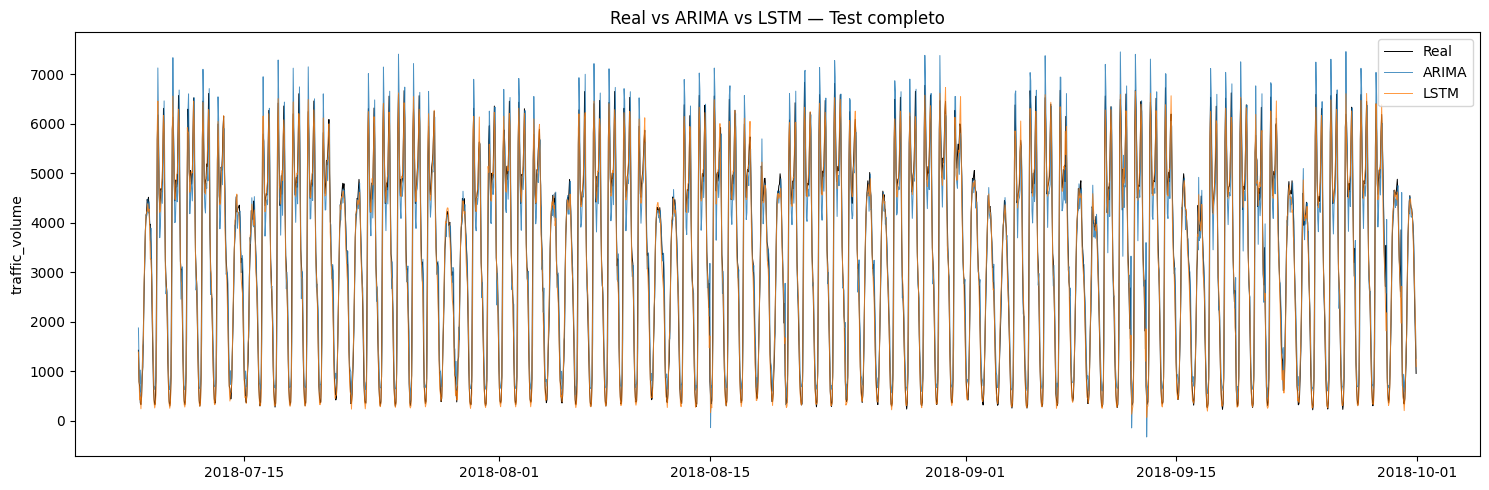

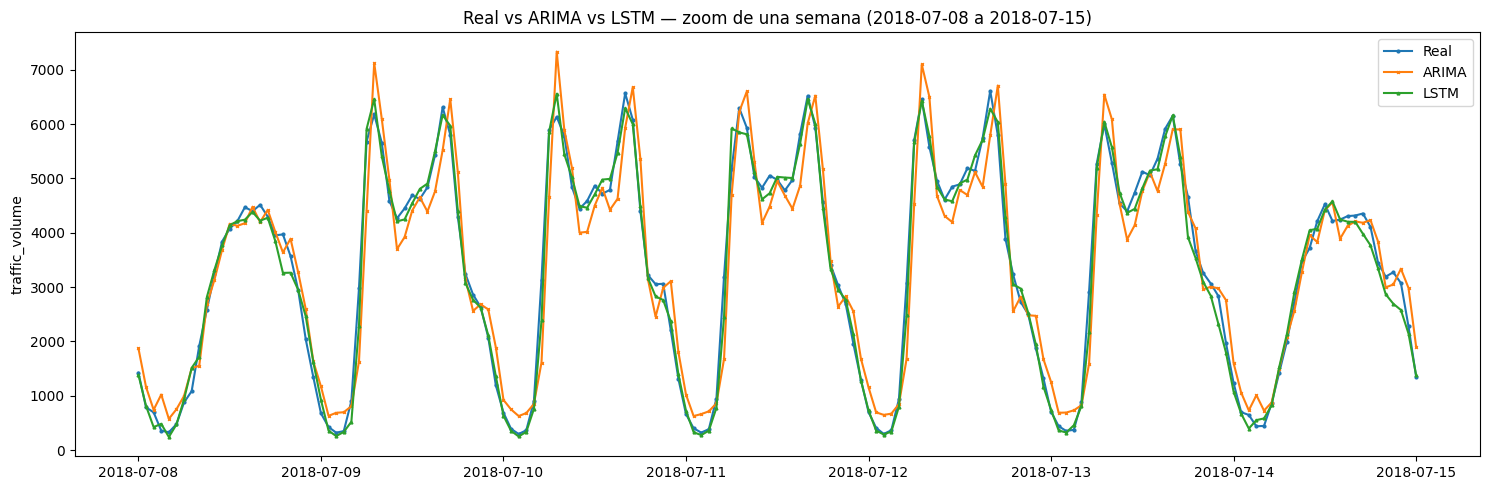

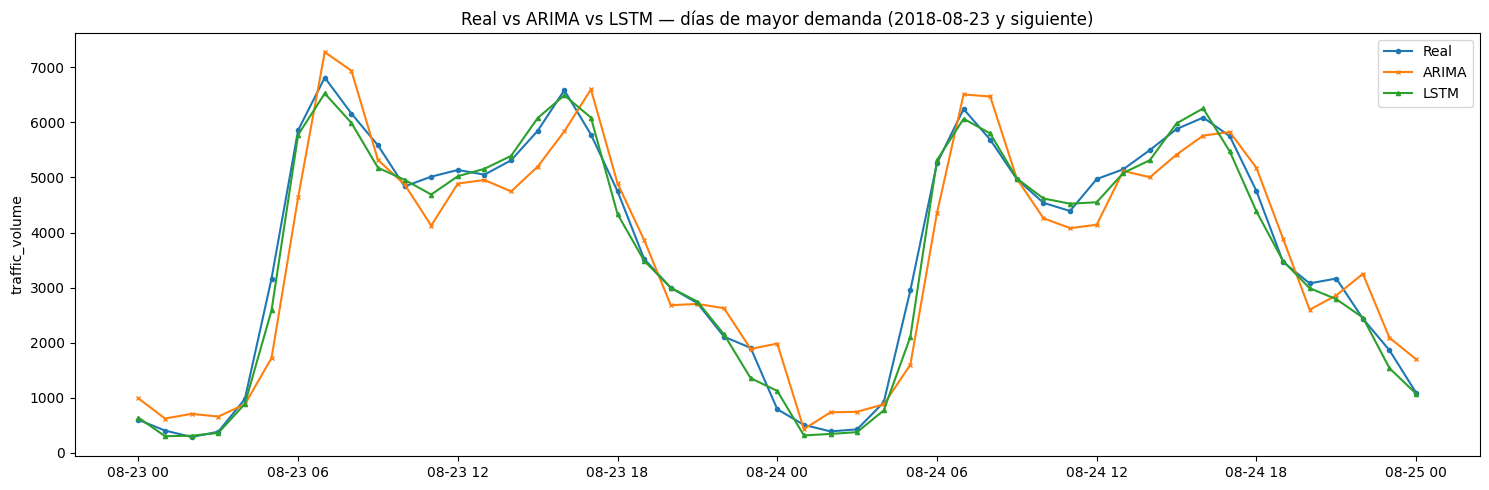

Día de mayor demanda promedio en Test: 2018-08-23  (promedio=3978.1)


In [32]:
# 1) Test completo (ventana común)
fig, ax = plt.subplots(figsize=(15, 5))
graficar_serie_vs_modelos(
    ax,
    [
        ("Real", serie_completa.loc[indice_comparacion, "traffic_volume"], {"linewidth": 0.7, "color": "black"}),
        ("ARIMA", y_pred_arima.loc[indice_comparacion], {"linewidth": 0.7, "alpha": 0.8}),
        ("LSTM", y_pred_lstm.loc[indice_comparacion], {"linewidth": 0.7, "alpha": 0.8}),
    ],
    "Real vs ARIMA vs LSTM — Test completo",
)
plt.tight_layout()
plt.show()

# 2) Zoom de una semana (primera semana de la ventana común)
semana_zoom_inicio = indice_comparacion[0]
semana_zoom_fin = semana_zoom_inicio + pd.Timedelta(days=7)
fig, ax = plt.subplots(figsize=(15, 5))
graficar_serie_vs_modelos(
    ax,
    [
        ("Real", serie_completa.loc[semana_zoom_inicio:semana_zoom_fin, "traffic_volume"], {"marker": "o", "markersize": 2}),
        ("ARIMA", y_pred_arima.loc[semana_zoom_inicio:semana_zoom_fin], {"marker": "x", "markersize": 2}),
        ("LSTM", y_pred_lstm.loc[semana_zoom_inicio:semana_zoom_fin], {"marker": "^", "markersize": 2}),
    ],
    f"Real vs ARIMA vs LSTM — zoom de una semana ({semana_zoom_inicio.date()} a {semana_zoom_fin.date()})",
)
plt.tight_layout()
plt.show()

# 3) Zoom del/los día(s) de mayor demanda dentro de la ventana común
promedio_diario_test = y_real_comparacion.groupby(y_real_comparacion.index.date).mean()
dia_max_demanda = pd.Timestamp(promedio_diario_test.idxmax())
zoom_pico_inicio = dia_max_demanda
zoom_pico_fin = dia_max_demanda + pd.Timedelta(days=2)

fig, ax = plt.subplots(figsize=(15, 5))
graficar_serie_vs_modelos(
    ax,
    [
        ("Real", serie_completa.loc[zoom_pico_inicio:zoom_pico_fin, "traffic_volume"], {"marker": "o", "markersize": 3}),
        ("ARIMA", y_pred_arima.loc[zoom_pico_inicio:zoom_pico_fin], {"marker": "x", "markersize": 3}),
        ("LSTM", y_pred_lstm.loc[zoom_pico_inicio:zoom_pico_fin], {"marker": "^", "markersize": 3}),
    ],
    f"Real vs ARIMA vs LSTM — días de mayor demanda ({dia_max_demanda.date()} y siguiente)",
)
plt.tight_layout()
plt.show()

print(f"Día de mayor demanda promedio en Test: {dia_max_demanda.date()}  (promedio={promedio_diario_test.max():.1f})")


### Desempeño durante horas pico

Primero se analizan los residuos (`error = real - predicción`) de ARIMA y LSTM: distribución, error medio y MAE por hora del día, para identificar en qué momentos aumentan los errores. Después se define una **hora pico reproducible** (`PEAK_THRESHOLD` = percentil 90 de `traffic_volume` calculado **solo con Train**) y se compara el error de ambos modelos dentro y fuera de picos.

Error medio ARIMA: 2.12   (desv. estándar: 552.25)
Error medio LSTM : 61.31   (desv. estándar: 255.80)


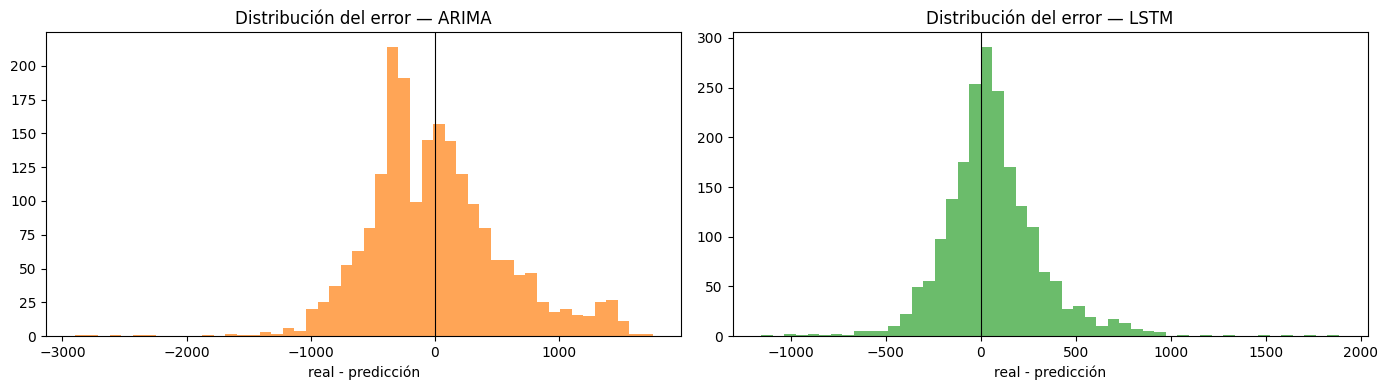

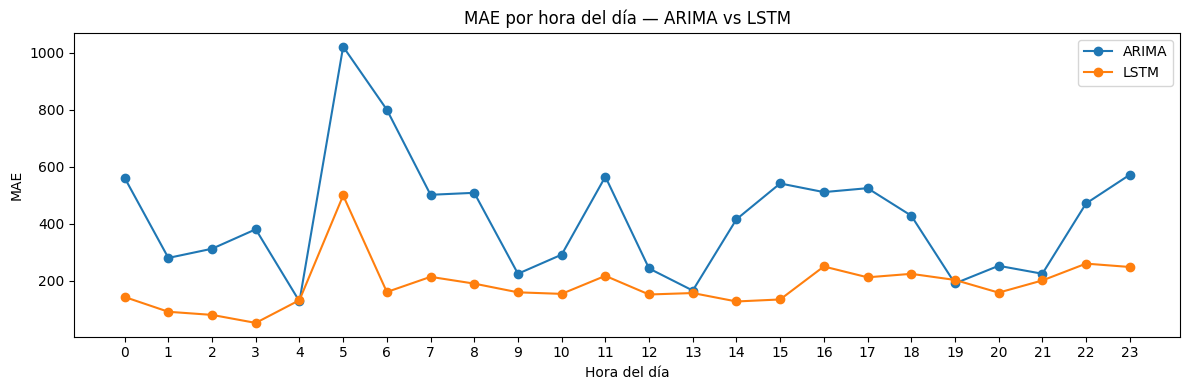


MAE por hora del día:
                 ARIMA        LSTM
date_time                         
0           561.436092  143.147693
1           280.314181   91.253990
2           312.588532   80.280825
3           380.865540   52.157295
4           127.882910  132.033815
5          1022.072196  499.540518
6           800.676697  160.691499
7           501.968589  213.866590
8           508.896299  190.109074
9           224.751490  159.536467
10          291.823288  154.100620
11          565.582759  217.414987
12          243.259511  151.928427
13          165.739769  157.000445
14          415.950694  127.411162
15          541.738095  134.489241
16          511.400856  250.247495
17          525.167467  212.216421
18          428.681897  224.413629
19          190.827630  203.025078
20          252.627763  158.450635
21          224.752715  201.222794
22          471.469346  260.291681
23          572.219570  248.495891


In [33]:
# Residuos (error = real - predicción) sobre la ventana común de evaluación
error_arima = y_real_comparacion - pred_arima_comp
error_lstm = y_real_comparacion - pred_lstm_comp

print(f"Error medio ARIMA: {error_arima.mean():.2f}   (desv. estándar: {error_arima.std():.2f})")
print(f"Error medio LSTM : {error_lstm.mean():.2f}   (desv. estándar: {error_lstm.std():.2f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(error_arima, bins=50, alpha=0.7, color="tab:orange")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Distribución del error — ARIMA")
axes[0].set_xlabel("real - predicción")

axes[1].hist(error_lstm, bins=50, alpha=0.7, color="tab:green")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Distribución del error — LSTM")
axes[1].set_xlabel("real - predicción")
plt.tight_layout()
plt.show()

# MAE por hora del día
mae_por_hora = pd.DataFrame({
    "ARIMA": error_arima.abs().groupby(error_arima.index.hour).mean(),
    "LSTM": error_lstm.abs().groupby(error_lstm.index.hour).mean(),
})

fig, ax = plt.subplots(figsize=(12, 4))
mae_por_hora.plot(ax=ax, marker="o")
ax.set_title("MAE por hora del día — ARIMA vs LSTM")
ax.set_xlabel("Hora del día")
ax.set_ylabel("MAE")
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

print("\nMAE por hora del día:")
print(mae_por_hora)


In [34]:
# Umbral de hora pico calculado ÚNICAMENTE con Train (sin fuga de información)
PEAK_THRESHOLD = entrenamiento["traffic_volume"].quantile(0.90)
print(f"PEAK_THRESHOLD (percentil 90 de traffic_volume en Train): {PEAK_THRESHOLD:.2f}")

is_peak_real = y_real_comparacion >= PEAK_THRESHOLD
print(f"Horas pico en la ventana de evaluación: {is_peak_real.sum()} de {len(is_peak_real)} ({is_peak_real.mean():.2%})")


PEAK_THRESHOLD (percentil 90 de traffic_volume en Train): 5858.00
Horas pico en la ventana de evaluación: 174 de 2036 (8.55%)


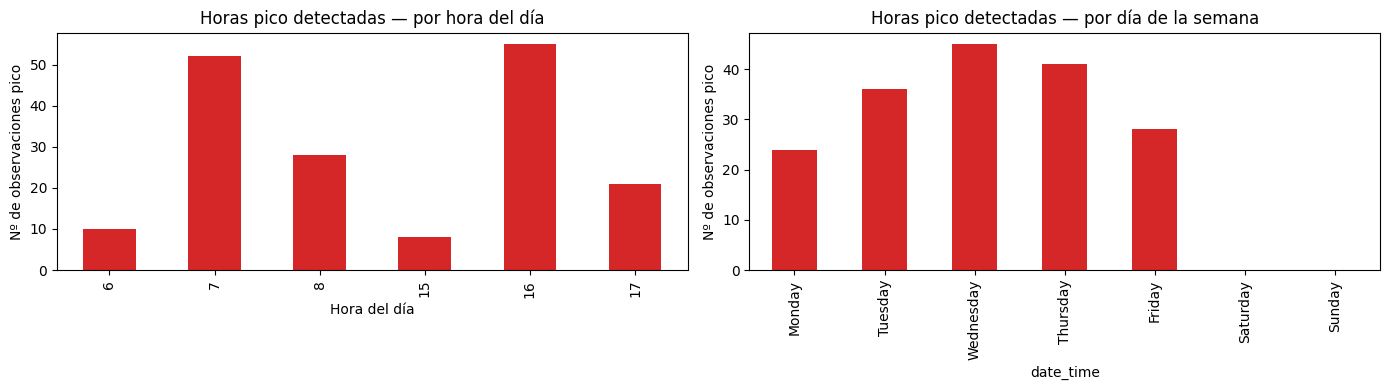

Tráfico promedio en horas pico: 6236.9
Tráfico promedio fuera de picos: 3090.3

Comparación de error dentro y fuera de horas pico:
       MAE en picos  MAE fuera de picos
ARIMA    656.021916          399.963997
LSTM     214.272455          181.555066


In [35]:
# Distribución de las horas pico: por hora del día y por día de la semana
horas_pico_test = y_real_comparacion.index[is_peak_real]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(horas_pico_test.hour).value_counts().sort_index().plot(kind="bar", ax=axes[0], color="tab:red")
axes[0].set_title("Horas pico detectadas — por hora del día")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("Nº de observaciones pico")

pd.Series(horas_pico_test.day_name()).value_counts().reindex(orden_dias).plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set_title("Horas pico detectadas — por día de la semana")
axes[1].set_ylabel("Nº de observaciones pico")
plt.tight_layout()
plt.show()

print(f"Tráfico promedio en horas pico: {y_real_comparacion[is_peak_real].mean():.1f}")
print(f"Tráfico promedio fuera de picos: {y_real_comparacion[~is_peak_real].mean():.1f}")

# Comparación del error de ARIMA y LSTM: picos vs no picos
mae_arima_pico = error_arima[is_peak_real].abs().mean()
mae_arima_no_pico = error_arima[~is_peak_real].abs().mean()
mae_lstm_pico = error_lstm[is_peak_real].abs().mean()
mae_lstm_no_pico = error_lstm[~is_peak_real].abs().mean()

tabla_picos = pd.DataFrame(
    {"MAE en picos": [mae_arima_pico, mae_lstm_pico], "MAE fuera de picos": [mae_arima_no_pico, mae_lstm_no_pico]},
    index=["ARIMA", "LSTM"],
)
print("\nComparación de error dentro y fuera de horas pico:")
print(tabla_picos)


### Interpretación crítica de la comparación

Todas las cifras siguientes provienen de la ejecución real sobre la ventana común de evaluación (2.036 horas de Test originalmente observadas).

**¿Cuál obtiene menor MAE?** La **LSTM** (184,35), muy por debajo del Baseline t-168 (235,27) y de ARIMA (421,85).

**¿Cuál obtiene menor RMSE?** También la **LSTM** (262,99), frente a 491,61 del Baseline t-168 y 552,12 de ARIMA. En esta ventana común, ARIMA queda incluso por debajo del baseline en RMSE, y el baseline supera a ARIMA en MAE.

**¿Cuál sigue mejor las horas pico?** La **LSTM**: en la gráfica de zoom de los días de mayor demanda (23-24 de agosto) y en la tabla de error dentro/fuera de picos, LSTM tiene MAE=214,27 en picos vs. 656,02 de ARIMA — ARIMA además produce sobreestimaciones marcadas en los picos (llega a superar los 7.000 y en algunos tramos del Test completo predice valores negativos, físicamente imposibles) mientras LSTM se mantiene mucho más ajustado a la forma real de la curva.

**¿En qué horas aumentan los errores?** El MAE por hora del día muestra que **ARIMA sufre su peor desempeño en la transición madrugada→mañana**: hora 5 (MAE≈1.022) y hora 6 (MAE≈801), el momento exacto en que el tráfico pasa abruptamente de mínimos nocturnos a niveles de hora pico — un patrón que un ARIMA no estacional, basado solo en 2 rezagos autorregresivos, no anticipa. LSTM también incrementa su error en esa misma franja (hora 5, MAE≈500) pero de forma mucho más moderada, y su error crece de forma más suave y acotada durante todas las horas pico de la tarde (16-18h).

**¿La LSTM aporta realmente una mejora frente a ARIMA?** Sí, y de forma sustancial: reduce el RMSE en ~52 % y el MAE en ~56 % frente a ARIMA en la misma ventana de evaluación, con menor error tanto dentro como fuera de horas pico, y sin las sobreestimaciones irreales (valores negativos) que produce ARIMA.

**¿La complejidad adicional está justificada?** Los resultados numéricos sugieren que sí: la mejora de la LSTM no es marginal (a diferencia de la ganancia casi nula que tuvo ARIMA sobre el baseline t-168), sino una reducción clara y consistente del error en todas las franjas horarias analizadas, incluidas las horas pico donde más importa acertar. El costo de esa complejidad (entrenamiento de ~350 s en tf-gpu, necesidad de escalar y construir secuencias de 168 horas) es razonable frente a la ganancia obtenida. Una evaluación final e integral de este trade-off, junto con la comparación frente al baseline y las conclusiones generales del proyecto, se abordará en la sección de conclusiones.

## Predicción futura

### RF-28 — Forecast ilustrativo de 24 horas (posterior al Test)

> **Esta sección es puramente ilustrativa y queda claramente separada de la evaluación histórica anterior.** Los números de desempeño (MAE, MSE, RMSE) reportados en las secciones previas —calculados sobre el conjunto de Test con datos reales conocidos— son y seguirán siendo **la evidencia principal y válida del desempeño de los modelos**. Lo que sigue no se evalúa contra ningún dato real (porque no existe), es solo una demostración de cómo se usaría el modelo para producir un pronóstico hacia adelante.

Se usa la **LSTM**, por ser el modelo con mejor desempeño en la comparación (RF-23–RF-27), para pronosticar las **24 horas siguientes** al último timestamp disponible en `serie_completa`.

**¿Cómo se realiza el forecast?** Se toma la última ventana de 168 horas reales (la misma longitud de secuencia con la que se entrenó la LSTM) como punto de partida, escalada con el mismo `escalador` (ajustado solo en Train, sin cambios respecto a la evaluación histórica).

**¿Es recursivo?** Sí. Para predecir la hora *t+1* se usa la ventana de las 168 horas reales más recientes. Pero para predecir *t+2* ya no hay un dato real en *t+1*: se usa la **propia predicción del modelo** como si fuera un valor observado, desplazando la ventana un paso. Esto se repite 24 veces, de modo que cada nueva predicción depende cada vez más de predicciones previas y cada vez menos de datos reales.

**¿Por qué puede acumular incertidumbre?** Porque cualquier error cometido en el paso 1 se propaga como si fuera un dato verdadero al paso 2, y ese error (más el nuevo error del paso 2) se propaga al paso 3, y así sucesivamente. No hay mecanismo de corrección: a diferencia de la evaluación en Test (donde cada predicción es *un paso adelante* y se compara con el dato real correspondiente), aquí el modelo nunca recibe una corrección basada en la realidad durante las 24 horas. Por eso el error esperado crece con el horizonte y las primeras horas del forecast son más confiables que las últimas.

**¿Por qué las métricas del Test son la evidencia principal?** Porque son las únicas donde existe un valor real contra el cual comparar cada predicción (MAE=184,35, RMSE=262,99 para la LSTM). El forecast futuro de 24 horas, en cambio, no puede validarse hasta que ocurra el futuro, y su error se irá revelando recién cuando existan datos reales — por diseño, **no debe presentarse como una certeza**, sino como una proyección razonable sujeta a una incertidumbre creciente.

Último timestamp con dato real disponible: 2018-09-30 23:00:00

Forecast ilustrativo (no validable, no es un dato real):
2018-10-01 00:00:00     566.561951
2018-10-01 01:00:00     283.979156
2018-10-01 02:00:00     197.316864
2018-10-01 03:00:00     325.348663
2018-10-01 04:00:00     899.468018
2018-10-01 05:00:00    2573.073242
2018-10-01 06:00:00    5012.819336
2018-10-01 07:00:00    5780.006836
2018-10-01 08:00:00    5304.323242
2018-10-01 09:00:00    4615.639648
2018-10-01 10:00:00    4258.930176
2018-10-01 11:00:00    4221.810059
2018-10-01 12:00:00    4338.947266
2018-10-01 13:00:00    4497.560547
2018-10-01 14:00:00    4731.953613
2018-10-01 15:00:00    5257.719727
2018-10-01 16:00:00    5829.836914
2018-10-01 17:00:00    5424.528320
2018-10-01 18:00:00    4115.949707
2018-10-01 19:00:00    3026.719971
2018-10-01 20:00:00    2651.083984
2018-10-01 21:00:00    2398.605469
2018-10-01 22:00:00    1854.975708
2018-10-01 23:00:00    1177.099243
Freq: h, Name: forecast_lstm_futuro, dt

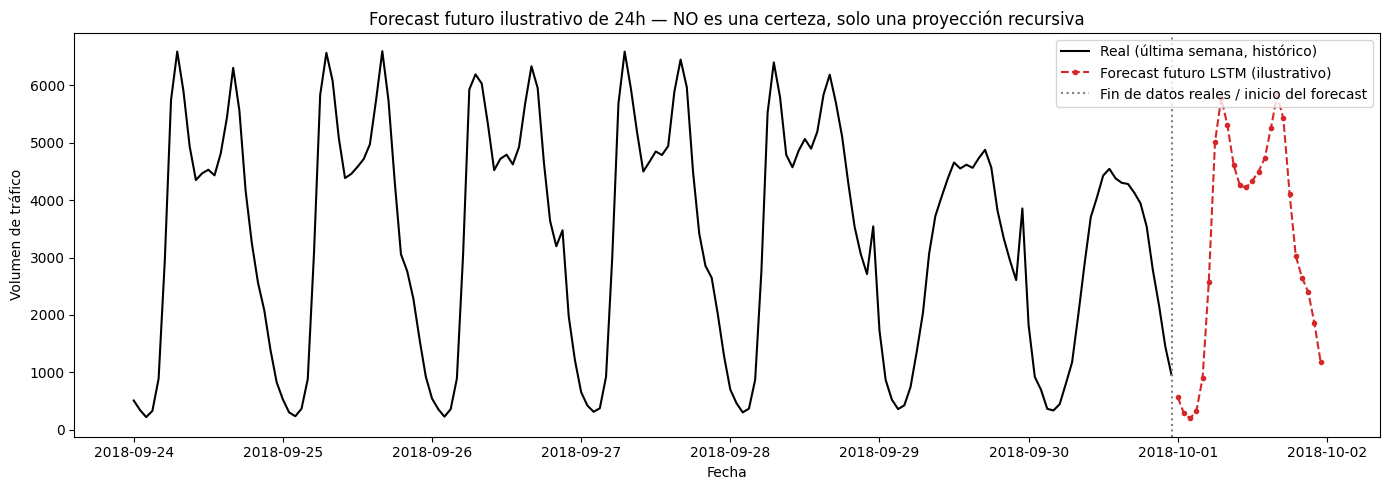

In [36]:
# Forecast futuro ilustrativo de 24h, recursivo, usando la LSTM (mejor modelo). NO se compara con datos reales: no existen.
HORIZONTE_FUTURO = 24
ultimo_timestamp_conocido = serie_completa.index[-1]
print(f"Último timestamp con dato real disponible: {ultimo_timestamp_conocido}")

ventana_inicial = serie_completa["traffic_volume"].iloc[-VENTANA_LSTM:].values.reshape(-1, 1)
ventana_escalada = escalador.transform(ventana_inicial).flatten().tolist()

predicciones_futuras_escaladas = []
for _ in range(HORIZONTE_FUTURO):
    entrada = np.array(ventana_escalada[-VENTANA_LSTM:]).reshape(1, VENTANA_LSTM, 1)
    pred_escalada = modelo_lstm.predict(entrada, verbose=0)[0, 0]
    predicciones_futuras_escaladas.append(pred_escalada)
    ventana_escalada.append(pred_escalada)  # recursivo: la predicción se retroalimenta como si fuera dato real

predicciones_futuras = escalador.inverse_transform(
    np.array(predicciones_futuras_escaladas).reshape(-1, 1)
).flatten()

timestamps_futuros = pd.date_range(
    start=ultimo_timestamp_conocido + pd.Timedelta(hours=1), periods=HORIZONTE_FUTURO, freq="h"
)
forecast_futuro = pd.Series(predicciones_futuras, index=timestamps_futuros, name="forecast_lstm_futuro")
print("\nForecast ilustrativo (no validable, no es un dato real):")
print(forecast_futuro)

# Visualización: historia reciente real (última semana) vs. forecast futuro, claramente separados
historia_reciente = serie_completa["traffic_volume"].iloc[-7 * 24:]

fig, ax = plt.subplots(figsize=(14, 5))
graficar_serie_vs_modelos(
    ax,
    [
        ("Real (última semana, histórico)", historia_reciente, {"color": "black"}),
        ("Forecast futuro LSTM (ilustrativo)", forecast_futuro, {"color": "tab:red", "linestyle": "--", "marker": "o", "markersize": 3}),
    ],
    "Forecast futuro ilustrativo de 24h — NO es una certeza, solo una proyección recursiva",
    ylabel="Volumen de tráfico",
)
ax.axvline(ultimo_timestamp_conocido, color="gray", linestyle=":", linewidth=1.5, label="Fin de datos reales / inicio del forecast")
ax.set_xlabel("Fecha")
ax.legend()

plt.tight_layout()
plt.show()

**Interpretación del forecast ilustrativo (RF-28):** el pronóstico recursivo de 24 horas (01/oct/2018) reproduce razonablemente la forma general del patrón diario ya visto en semanas anteriores —valores bajos de madrugada (00:00–04:00), ascenso hacia un pico matutino cercano a las 07:00–08:00 (≈5.300–5.800) y un segundo pico por la tarde alrededor de las 16:00 (≈5.830)—, lo cual es razonable porque la LSTM aprendió esa estacionalidad diaria durante el entrenamiento. Sin embargo, esto **no constituye evidencia de desempeño**: no hay ningún valor real de tráfico para el 1 de octubre de 2018 contra el cual contrastar esta curva. Como se explicó arriba, al ser recursivo, cada hora predicha se apoya en predicciones previas y no en observaciones reales, por lo que la incertidumbre crece con el horizonte — las primeras horas (más cercanas al último dato real) son más confiables que las últimas. La referencia válida y verificable del desempeño de la LSTM sigue siendo, exclusivamente, la evaluación sobre el conjunto de Test (MAE=184,35, RMSE=262,99).

## Análisis y conclusiones

### Resumen del trabajo realizado

1. **Auditoría y preparación temporal**: se cargó `Metro_Interstate_Traffic_Volume.csv` (48.204 filas), se auditaron 5.445 timestamps duplicados (sin valores en conflicto) y se consolidó un único registro por hora. Se detectó una cobertura horaria de solo 77,2 % sobre el histórico completo, con un hueco dominante de 7.386 horas (ago-2014 a jun-2015) que **no se interpoló**. Por esa razón, el modelado se restringió al período denso 2017-01-01 a 2018-09-30 (cobertura >99,5 %), regularizado a frecuencia horaria exacta (15.312 posiciones, 66 imputadas mediante medianas por día de la semana y hora, calculadas únicamente con Train) y dividido cronológicamente en Train (10.920 h), Validation (2.184 h) y Test (2.208 h), sin aleatorizar.
2. **Análisis exploratorio (EDA)**: se identificó un ciclo diario bimodal en días laborales (pico principal ≈16:00 con ≈5.709 vehículos/hora, pico secundario ≈07:00 con ≈4.770), una caída marcada los fines de semana (domingo ≈2.426 frente a ≈3.300-3.675 entre semana) y una fuerte estacionalidad diaria confirmada por la ACF (picos de autocorrelación cada 24 horas).
3. **Modelo base de referencia**: se implementaron dos baselines ingenuos —repetir el valor de 24 horas antes (`t-24`, RMSE=968,61) y de 168 horas antes (`t-168`, RMSE=552,96)— evaluados solo sobre horas de Test originalmente observadas.
4. **ARIMA**: tras confirmar estacionariedad con ADF (`d=0`) y acotar candidatos con ACF/PACF, se seleccionó `ARIMA(2,0,0)` por RMSE en Validation (walk-forward por bloques de 24h). Evaluado sobre Test con protocolo one-step-ahead/walk-forward, obtuvo MAE=418,24, RMSE=548,76 — solo marginalmente mejor que el baseline `t-168`.
5. **LSTM**: con ventana de 168 horas, escalado ajustado solo con Train y arquitectura `LSTM(50)→LSTM(50)→Dense(25)→Dense(1)`, el entrenamiento se detuvo por `EarlyStopping` en la época 21 sin señales de sobreajuste. Evaluada sobre el mismo Test, obtuvo MAE=184,35, RMSE=262,99, reduciendo el error a menos de la mitad frente a ARIMA y al baseline.
6. **Comparación de modelos y horas pico**: sobre una ventana común de evaluación (2.036 horas), se compararon Baseline `t-168`, ARIMA y LSTM mediante tablas y gráficas (Test completo, zoom semanal, zoom de días de mayor demanda), se analizaron los residuos y el MAE por hora del día, y se definió un umbral reproducible de hora pico (percentil 90 de Train, `PEAK_THRESHOLD=5.858`) para comparar el error dentro y fuera de picos.
7. **Predicción futura ilustrativa (RF-28)**: se generó un forecast recursivo de 24 horas con la LSTM, claramente separado de la evaluación histórica y explícitamente presentado como una proyección no verificable, no como una certeza.

### Resultados comparativos

Métricas reales sobre la ventana común de evaluación (2.036 horas de Test originalmente observadas):

| Modelo | MAE | MSE | RMSE |
|---|---:|---:|---:|
| Baseline (t-168) | 235,27 | 241.678,60 | 491,61 |
| ARIMA(2,0,0) | 421,85 | 304.832,20 | 552,12 |
| **LSTM** | **184,35** | **69.161,39** | **262,99** |

Comparación del error absoluto medio dentro y fuera de horas pico (umbral = percentil 90 de `traffic_volume` en Train, `PEAK_THRESHOLD=5.858`; 174 de 2.036 horas evaluadas fueron pico, 8,55 %):

| Modelo | MAE en picos | MAE fuera de picos |
|---|---:|---:|
| ARIMA(2,0,0) | 656,02 | 399,96 |
| **LSTM** | **214,27** | **181,56** |

El tráfico promedio observado en horas pico fue de 6.236,9 frente a 3.090,3 fuera de picos. Las horas pico detectadas se concentran en 07:00 y 16:00, exclusivamente en días laborables (lunes a viernes; ninguna observación pico cayó en sábado o domingo dentro de la ventana de Test).

### Interpretación crítica

**Comportamiento temporal del tráfico.** El EDA mostró un patrón bimodal muy estable en días laborales (picos ≈07:00 y ≈16:00) y una caída marcada los fines de semana, con fuerte autocorrelación cada 24 horas. Este patrón es el que explica, en gran medida, por qué el baseline `t-168` (repetir el valor de la semana anterior) ya es un predictor competitivo: la estacionalidad semanal es tan fuerte que "lo que pasó la semana pasada a esta hora" resulta casi tan informativo como un modelo ajustado.

**Baseline.** El baseline `t-24` (RMSE=968,61) es claramente inferior al `t-168` (RMSE=552,96), lo que confirma que el ciclo semanal es más informativo que el diario simple para este dataset: comparar un lunes con el domingo anterior (`t-24`) es peor que compararlo con el lunes anterior (`t-168`).

**ARIMA.** `ARIMA(2,0,0)`, evaluado con protocolo one-step-ahead/walk-forward, obtiene un RMSE (548,76 en su ventana propia; 552,12 en la ventana común) prácticamente empatado con el baseline `t-168`, y en la ventana común incluso lo supera ligeramente en RMSE aunque no en MAE. Al no ser un modelo estacional, ARIMA no incorpora explícitamente el ciclo de 24 horas detectado en la ACF, lo que se traduce en errores grandes en las transiciones abruptas madrugada→hora pico (MAE por hora ≈1.022 a las 05:00 y ≈801 a las 06:00) y en predicciones que llegan a tomar valores negativos, físicamente imposibles.

**LSTM.** Con una ventana de contexto de 168 horas, la LSTM reduce el MAE y el RMSE a menos de la mitad frente a ARIMA y frente al baseline (MAE=184,35, RMSE=262,99), y su error crece de forma mucho más moderada en las mismas horas de transición (MAE≈500 a las 05:00 frente a ≈1.022 de ARIMA).

**Comparación cuantitativa.** Sobre la misma ventana de evaluación: LSTM obtiene el menor MAE (184,35) y el menor RMSE (262,99); ARIMA es el peor en ambas métricas (421,85 / 552,12); el baseline `t-168` queda en un punto intermedio (235,27 / 491,61). La mejora de LSTM frente a ARIMA es de aproximadamente 56 % en MAE y 52 % en RMSE, una diferencia sustancialmente mayor que la ganancia casi nula de ARIMA frente al baseline.

**Comportamiento durante tráfico alto (picos).** Con el umbral reproducible `PEAK_THRESHOLD=5.858` (percentil 90 de Train), LSTM mantiene un MAE de 214,27 en picos frente a 656,02 de ARIMA — una brecha aún mayor que en el resto del tiempo (181,56 vs. 399,96 fuera de picos). Es decir, la ventaja de LSTM no solo se sostiene en las horas de mayor congestión, sino que se acentúa, justamente donde más importa acertar.

**Limitaciones metodológicas.** (1) El experimento se apoya en un único punto de conteo vial, no en toda una red o ciudad. (2) Existe un hueco histórico enorme (ago-2014 a jun-2015) que obligó a restringir el modelado a 2017-2018. (3) Ambos modelos principales son univariados: no usan variables meteorológicas ni de calendario (`holiday`, `temp`, `weather_main`, etc.), aunque el dataset las contiene. (4) `ARIMA(2,0,0)` no es estacional, por lo que no captura explícitamente el ciclo de 24 horas — una limitación reconocida del diseño, no un error de ajuste. (5) La LSTM depende de la elección de la ventana (168 h) y de hiperparámetros que no se exploraron exhaustivamente por restricciones de tiempo de cómputo. (6) El análisis de horas pico es un análisis secundario derivado de las predicciones y no debe interpretarse como un problema de clasificación en sí mismo.

**Sobre correlación y causalidad.** Todos los patrones descritos (hora, día de la semana, volumen de tráfico) son **asociaciones temporales observadas en los datos**, no relaciones causales demostradas: no se afirma, por ejemplo, que "ser lunes cause" un mayor tráfico, sino que el volumen medido los lunes tiende a ser mayor que el de un domingo. Cualquier factor externo (clima, eventos, temporada) que pudiera explicar estos patrones se plantea aquí únicamente como hipótesis razonable, no como relación causal comprobada, ya que dichas variables no se incorporaron a los modelos principales.

No se declara superioridad de ningún modelo basándose solo en la inspección visual de las gráficas: la conclusión de que LSTM es el modelo preferible en este experimento se sustenta en las métricas cuantitativas reales reportadas arriba (MAE, RMSE, y error en picos vs. no picos), coherentes entre sí y con lo observado gráficamente.

### Conclusión general

Con base exclusivamente en los resultados numéricos obtenidos, la **LSTM** fue el modelo con mejor desempeño para predecir el volumen horario de tráfico vehicular en este experimento: menor MAE (184,35) y menor RMSE (262,99) que ARIMA y que el baseline `t-168` sobre la misma ventana de evaluación, con una ventaja que se mantiene —e incluso se amplía— durante las horas pico (MAE=214,27 vs. 656,02 de ARIMA). Esta conclusión no se basa en la apariencia visual de las gráficas, sino en la comparación cuantitativa de métricas calculadas sobre exactamente los mismos timestamps para los tres modelos.

Al mismo tiempo, los resultados matizan el valor de la complejidad adicional: `ARIMA(2,0,0)` apenas superó al baseline ingenuo `t-168` (RMSE 548,76 vs. 552,96 en su ventana propia), lo que indica que, para esta serie con fuerte estacionalidad semanal, un modelo estadístico simple y no estacional aporta poco frente a repetir el patrón de la semana anterior. La LSTM sí justificó su mayor complejidad: la magnitud de la mejora (~50 % de reducción de error) es sustancialmente mayor que el costo adicional de entrenamiento (~350 s en GPU) y de preprocesamiento (escalado, construcción de secuencias de 168 horas).

El pronóstico futuro ilustrativo de 24 horas (RF-28) reforzó, de forma cualitativa, que la LSTM reproduce razonablemente el patrón diario aprendido, pero se reitera que ese ejercicio **no constituye evidencia de desempeño**: la evidencia válida sigue siendo, exclusivamente, la evaluación sobre el conjunto de Test con datos reales.

Estos hallazgos están acotados a un único punto de conteo vial, a un período histórico específico (2017-2018) y a modelos univariados; no deben generalizarse sin más a otras vías, ciudades o períodos sin una validación adicional.

### Limitaciones

- El contador de tráfico representa un punto vial específico (la interestatal Metro, Minneapolis-St Paul), no toda una ciudad ni una red vial completa.
- Existen períodos históricos faltantes (el hueco de ago-2014 a jun-2015 obligó a acotar el modelado a 2017-2018).
- Una fracción de la serie (66 horas, 0,43 % del período denso) debió regularizarse mediante imputación por mediana, condicionada a día de la semana y hora, calculada solo con Train.
- Los modelos principales (ARIMA y LSTM) son univariados: solo usan el historial de `traffic_volume`.
- No se incorporan variables meteorológicas (`temp`, `weather_main`, etc.) ni de calendario (`holiday`) en el experimento principal, pese a estar disponibles en el dataset.
- `ARIMA(2,0,0)` es un modelo simple, no estacional: no modela explícitamente el ciclo diario de 24 horas ni la estacionalidad semanal detectados en el EDA.
- La LSTM requiere seleccionar una ventana de secuencia (168 h) e hiperparámetros (unidades, capas, batch size) que no se exploraron de forma exhaustiva.
- El forecast futuro ilustrativo (RF-28) es recursivo y no implica ninguna garantía ni certeza sobre el tráfico real futuro.

### Trabajo futuro

Como posibilidades razonables para extender este trabajo, sin haberse implementado aquí:

- modelos SARIMA/SARIMAX que capturen explícitamente la estacionalidad diaria y semanal;
- incorporar `holiday` como variable exógena;
- incorporar `temp` y otras variables meteorológicas continuas;
- incorporar `weather_main` como variable categórica;
- una LSTM multivariada que combine tráfico con clima y calendario;
- arquitecturas alternativas como GRU o mecanismos de atención;
- forecasting multistep (más allá de un solo paso adelante);
- predicción probabilística (intervalos de confianza en vez de un único valor puntual);
- comparación con otros modelos de series temporales o de machine learning (p. ej. XGBoost);
- extender el análisis a otros puntos de conteo o a una red vial completa.

## Referencias

1. Dataset: *Metro Interstate Traffic Volume*. Kaggle. https://www.kaggle.com/datasets/mikedev/metro-traffic-volume
2. Material de la asignatura Machine Learning (Maestría en Inteligencia Artificial, Universidad de la Salle) sobre redes LSTM y series temporales.